### [Github' Matheus S. Silva](https://github.com/CCT-Dublin/CCT_STDA_CA_01_40S/blob/main/notebooks/CCT_STDA_CA_01_40S_2026438.ipynb)

## 🏦 Business Problem Definition

This project aims to investigate credit card transactions using descriptive and inferential statistical techniques. The analysis focuses on understanding transaction characteristics, identifying patterns associated with fraudulent activities, and applying probability distributions to real-world financial data.

The statistical analysis will be conducted using Python, with particular attention to the Binomial, Poisson, and Normal distributions. The findings will be interpreted to evaluate the suitability of each statistical distribution for describing the selected dataset.

**🎯 Objectives:**

- Explore and understand the structure of the dataset.
- Perform descriptive statistical analysis.
- Investigate the distribution of fraudulent and
  legitimate transactions.
- Apply the Binomial distribution to model
  fraudulent transaction occurrences.
- Apply the Poisson distribution to investigate
  transaction counts over defined time intervals.
- Investigate the suitability of the Normal
  distribution for selected numerical variables.
- Compare and critically evaluate the statistical
  distributions used in the analysis.

**Dataset Description**

The dataset used in this project was obtained from Kaggle and published by the Machine Learning Group at the Université Libre de Bruxelles (ULB). It contains anonymized [credit card transactions](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud), with 28 PCA-transformed features, alongside the transaction time, amount, and fraud classification label (Machine Learning Group - ULB, n.d.).

**Dataset Features**

The dataset contains 31 columns:

- Time: Seconds elapsed since the first transaction.
- V1–V28: Anonymised numerical features obtained through Principal Component Analysis (PCA).
- Amount: Monetary value of each transaction.
- Class: Target variable identifying fraudulent and legitimate transactions.

The target variable is defined as:

- 0 = Legitimate transaction
- 1 = Fraudulent transaction

**Dataset Characteristics**

One important characteristic of this dataset is its highly imbalanced class distribution.Fraudulent transactions represent approximately 0.172% of all observations. This imbalance must be considered when interpreting statistical results.

### 🔄 Download the libraries if you don't have them!

In [1]:
# !pip install -r ../requirements.txt

### 🤔 JupyterLab Authoring ©

In [2]:
%reload_ext watermark
%watermark --author "Matheus DoS S. Silva"
%watermark --email "2026438@student.cct.ie"
%watermark --github_username "MattheuSxS"
%watermark --date
%watermark --python

Author: Matheus DoS S. Silva

Email: 2026438@student.cct.ie

Github username: MattheuSxS

Date: 2026-11-01

Python implementation: CPython
Python version       : 3.14.10
IPython version      : 9.17.1



### 🛂 Importing Packages

This is the workspace preparation phase. Here, we load all the necessary Python tools and libraries (such as Pandas for data manipulation, Scikit-learn for modeling, and Matplotlib/Seaborn for visualizations) that will be used throughout the project.

In [3]:
import logging
import kagglehub
import numpy as np
import pandas as pd        # Data manipulation and analysis.
import seaborn as sns
from scipy import stats
from pathlib import Path
import matplotlib.pyplot as plt


# Display settings
sns.set_style('whitegrid')
%matplotlib inline

In [4]:
logging.basicConfig(
    format=("%(asctime)s | %(levelname)s | File_name ~> %(module)s.py "
            "| Function ~> %(funcName)s | Line ~~> %(lineno)d  ~~>  %(message)s"),
    level=logging.INFO
)

### 🔄 Data Loading and Initial Inspection

This is the first encounter with the project's raw material. We load the data from a source (in our case, a CSV file) into a Pandas DataFrame and perform an initial check to understand its structure.

The download_dataset() function is responsible for loading the dataset used in the Machine Learning project. 
* **1 ~~>** It first checks whether the dataset already exists locally in the ../data directory.
* **2 ~~>** If the file is not found, it attempts to download the dataset from the kaggle using the kagglehub function.
 
Once the dataset is available, the function loads it into a Pandas DataFrame and returns it for further data analysis and Machine Learning processing. The function also includes logging and exception handling to provide information about the download and loading process.

In [5]:
def download_dataset() -> pd.DataFrame:
    data_dir = Path("../data")
    dataset_file = data_dir / "creditcard.csv"

    data_dir.mkdir(parents=True, exist_ok=True)

    try:
        if not dataset_file.exists():

            logging.warning("📥 Dataset not found. Downloading from Kaggle...")

            path = kagglehub.dataset_download(
                "mlg-ulb/creditcardfraud",
                output_dir=str(data_dir)
            )

            logging.info(f"✅ Dataset downloaded to: {path}")

        else:

            logging.info(f"✅ Dataset already exists: {dataset_file}")

        return  pd.read_csv(dataset_file, sep=",")

    except Exception as e:
        logging.error(f"❌ Failed to download or read the dataset: {e}")

In [6]:
df = download_dataset()

2026-11-01 22:44:12,593 | INFO | File_name ~> 343154615.py | Function ~> download_dataset | Line ~~> 21  ~~>  ✅ Dataset already exists: ../data/creditcard.csv


In [7]:
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
print(f"Dataset dimensions: {df.shape}")

Number of rows: 284,807
Number of columns: 31
Dataset dimensions: (284807, 31)


**📍 Variable Information:**

* **Time:** Seconds elapsed between each transaction and the first transaction.
* **V1–V28:** Anonymised numerical features obtained through Principal Component Analysis (PCA).
* **Amount:** Transaction amount.
* **Class:** Target variable identifying fraudulent (1) and legitimate (0) transactions.

In [8]:
print(f"Dataset columns: {list(df.columns)}")


Dataset columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [10]:
df.dtypes.value_counts()

float64    30
int64       1
Name: count, dtype: int64

In [11]:
df.head(n=3)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0


In [12]:
df.tail(n=3)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [13]:
df.sample(n=3, random_state=42)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
43428,41505.0,-16.526507,8.584972,-18.649853,9.505594,-13.793819,-2.832404,-16.701694,7.517344,-8.507059,...,1.190739,-1.127670,-2.358579,0.673461,-1.413700,-0.462762,-2.018575,-1.042804,364.19,1
49906,44261.0,0.339812,-2.743745,-0.134070,-1.385729,-1.451413,1.015887,-0.524379,0.224060,0.899746,...,-0.213436,-0.942525,-0.526819,-1.156992,0.311211,-0.746647,0.040996,0.102038,520.12,0
29474,35484.0,1.399590,-0.590701,0.168619,-1.029950,-0.539806,0.040444,-0.712567,0.002299,-0.971747,...,0.102398,0.168269,-0.166639,-0.810250,0.505083,-0.232340,0.011409,0.004634,31.00,0


In [14]:
missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (
        df.isnull().mean() * 100
    ).round(4)
})

missing_values.sort_values(
    by='Missing Values',
    ascending=False
)

,Missing Values,Missing Percentage
Time,0,0.0
V16,0,0.0
Amount,0,0.0
V28,0,0.0
V27,0,0.0
V26,0,0.0
V25,0,0.0
V24,0,0.0
V23,0,0.0
V22,0,0.0


Your result showed zero missing values ​​across all 31 columns.

This means that:
- We did not identify any NaN values.
- There is no need to apply imputation techniques at this stage.
- All variables have 284,807 non-null observations.

In [15]:
duplicate_count = df.duplicated().sum()

duplicate_percentage = (
    duplicate_count / len(df)
) * 100

print(f"Duplicate records: {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_percentage:.4f}%")

Duplicate records: 1,081
Duplicate percentage: 0.3796%


#### **⚠⚠ Important: ⚠⚠**

Following the initial data quality assessment,1,081 duplicate records were identified.
A further investigation is necessary to understandhow these duplicated observations are distributed across the target variable. This analysis will examine the relationship between
duplicate records and transaction classes to determine whether removing them could affect the statistical distribution of legitimate and fraudulent transactions.

🚫 No records will be removed before evaluating their potential impact on the dataset. 🚫

In [16]:
duplicated_records = df[
    df.duplicated()
].copy()

print(f"Distribution of duplicated records by: {duplicated_records['Class']
    .value_counts()
    .sort_index()}")

Distribution of duplicated records by: Class
0    1062
1      19
Name: count, dtype: int64


In [17]:
cleaned_distribution = (
    df.drop_duplicates()['Class']
    .value_counts()
    .sort_index()
)

comparison = pd.DataFrame({
    'Original': df['Class'].value_counts().sort_index(),
    'After Removing Duplicates': cleaned_distribution
})

comparison['Difference'] = (
    comparison['Original'] -
    comparison['After Removing Duplicates']
)

comparison

,Original,After Removing Duplicates,Difference
Class,,,
0,284315,283253,1062
1,492,473,19


In [18]:
original_fraud_rate = (
    df['Class'].mean() * 100
)

cleaned_df = df.drop_duplicates().copy()

cleaned_fraud_rate = (
    cleaned_df['Class'].mean() * 100
)
duplicated_records
print(f"Original fraud rate: {original_fraud_rate:.4f}%")
print(f"Fraud rate after removing duplicates: {cleaned_fraud_rate:.4f}%")
print(f"Difference: {cleaned_fraud_rate - original_fraud_rate:.4f} percentage points")

Original fraud rate: 0.1727%
Fraud rate after removing duplicates: 0.1667%
Difference: -0.0060 percentage points


In [19]:
all_duplicated_records = df[df.duplicated(keep=False)].copy()

print(f"Total observations involved in duplicates: {len(all_duplicated_records):,}")
print(f"Observations: {
    all_duplicated_records['Class']
    .value_counts()
    .sort_index()}")

Total observations involved in duplicates: 1,854
Observations: Class
0    1822
1      32
Name: count, dtype: int64


**⚠⚠ Important: ⚠⚠** 

The duplicate records investigation identified `1,081` additional duplicate observations, representing approximately `0.38%` of the original dataset.
A further investigation using the `keep=False` parameter identified `1,854` observations belonging to duplicate groups, including both the original records and their repeated occurrences.
Among the `1,081` additional duplicate observations, `1,062` belonged to legitimate transactions and 19 belonged to fraudulent transactions.
The analysis also revealed that removing duplicate records changes the observed fraud proportion from `0.1727%` to `0.1667%`, representing a decrease of `0.0060` percentage points.
Although the overall proportion of duplicate observations is relatively small, their impact on the fraudulent class is more significant. The removal of 19 additional fraudulent observations represents apprximately `3.86%` of the original fraudulent transactions.
These findings demonstrate that duplicate removal can influence the statistical characteristics of the dataset, particularly the distribution of the target variable.
Consequently, the original dataset will be preserved for the initial statistical investigation, while the potential impact of deduplication will be considered when interpreting the results.

#### 

In [20]:
print(f"Unique values in Class: {df['Class'].unique()}")

Unique values in Class: [0 1]


In [21]:
print(f"Target variable distribution: {df['Class'].value_counts(dropna=False)}")

Target variable distribution: Class
0    284315
1       492
Name: count, dtype: int64


In [22]:
expected_columns = (
    ['Time']
    + [f'V{i}' for i in range(1, 29)]
    + ['Amount', 'Class']
)

print(f"Expected columns: {set(expected_columns) == set(df.columns)}")
print(f"Negative transaction amounts: {(df['Amount'] < 0).sum()}")
print(f"Negative time values: {(df['Time'] < 0).sum()}")
print(f"Unexpected Class values: {(~df['Class'].isin([0, 1])).sum()}")

Expected columns: True
Negative transaction amounts: 0
Negative time values: 0
Unexpected Class values: 0


# 🕵🏾 Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the main characteristics, patterns, and statistical properties of the dataset. we will focuses on examining the distribution of variables, identifying relationships between features, and investigating differences between legitimate and fraudulent transactions. Descriptive statistics and appropriate visualizations will be used to support the analysis and provide insights into the characteristics of credit card transactions.

In [23]:
numerical_features = df.drop(columns=['Class'])
numerical_features.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


* **Skewness:** Indicates whether the data exhibit a symmetric distribution or have a longer tail in a particular direction.
  * Approximately 0 ~~> Symmetric
  * Positive ~~> Right-skewed
  * Negative ~~> Left-skewed

* **Kurtosis:** It helps characterize the weight of the tails and the concentration of the distribution in comparison to a Normal distribution.

In [24]:
pd.DataFrame({
    'Skewness': numerical_features.skew(),
    'Kurtosis': numerical_features.kurt()
})

,Skewness,Kurtosis
Time,-0.035568,-1.293530
V1,-3.280667,32.486679
V2,-4.624866,95.773106
V3,-2.240155,26.619551
V4,0.676292,2.635455
V5,-2.425901,206.904560
V6,1.826581,42.642494
V7,2.553907,405.607417
V8,-8.521944,220.586974
V9,0.554680,3.731311


Why are we doing this?

Because we want to understand:
- Whether transaction values show significant variability.
- Whether there are differences between the mean and the median.
- Whether the distribution exhibits asymmetry.
- Whether there are extreme values (outliers).
- Whether the variables display characteristics consistent or inconsistent with a Normal distribution.

In [25]:
selected_stats = df[['Amount', 'Time']].describe().T
selected_stats['Variance'] = (df[['Amount', 'Time']].var())
selected_stats['Skewness'] = (df[['Amount', 'Time']].skew())
selected_stats['Kurtosis'] = (df[['Amount', 'Time']].kurt())

selected_stats

,count,mean,std,min,25%,50%,75%,max,Variance,Skewness,Kurtosis
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16,6.256007e+04,16.977724,845.092646
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00,2.255124e+09,-0.035568,-1.293530


In [26]:
df.groupby('Class')[['Amount', 'Time']].agg(['count','mean','median','std','min','max']).T

Class                      0              1
Amount count   284315.000000     492.000000
       mean        88.291022     122.211321
       median      22.000000       9.250000
       std        250.105092     256.683288
       min          0.000000       0.000000
       max      25691.160000    2125.870000
Time   count   284315.000000     492.000000
       mean     94838.202258   80746.806911
       median   84711.000000   75568.500000
       std      47484.015786   47835.365138
       min          0.000000     406.000000
       max     172792.000000  170348.000000

#### 🗂 Auxiliary Functions

In [27]:
def F_barplot(data:pd.DataFrame, column:str) -> None:
    label_counts = data[column].value_counts().sort_index()
    label_percentages = label_counts / label_counts.sum() * 100
    
    sns.set_theme(style="whitegrid", context="notebook")
    
    fig, ax = plt.subplots(figsize=(10, 5))
    
    sns.barplot(
        x = label_counts.index,
        y = label_counts.values,
        hue = label_counts.index,
        palette = {0: "steelblue", 1: "indianred"},
        legend = False,
        ax = ax
    )
    
    ax.set_title("Distribution of Transaction Classes", fontsize = 16, fontweight = "bold", pad = 15)
    ax.set_xlabel("Transaction Class", fontsize = 12, labelpad = 10)
    ax.set_ylabel("Number of Transactions", fontsize = 12, labelpad = 10)
    
    for i, (count, percentage) in enumerate(
        zip(label_counts.values, label_percentages.values)
    ):
        ax.annotate(
            f"{count:,.0f}\n({percentage:.2f}%)",
            xy = (i, count),
            xytext = (0, 6),
            textcoords = "offset points",
            ha = "center",
            fontsize = 10,
            fontweight = "bold"
        )
    
    ax.grid(axis = "y", linestyle = "--", alpha = 0.4)
    ax.grid(axis = "x", visible = False)
    sns.despine()
    
    plt.tight_layout()
    plt.show()

In [28]:
def F_Subplot(data:pd.DataFrame, column:str) -> None:
    class_percentage = (
        df[column]
        .value_counts(normalize=True)
        .sort_index() * 100
    )
    
    fig, ax = plt.subplots(figsize=(5, 5))
    
    colors = ['#4472C4', '#E15759']
    
    wedges, texts, autotexts = ax.pie(
        class_percentage,
        labels = None,
        autopct = '%1.3f%%',
        startangle = 90,
        colors = colors,
        pctdistance = 0.78,
        wedgeprops = {
            'width': 0.38,
            'edgecolor': 'white',
            'linewidth': 2
        }
    )
    
    for text in autotexts:
        text.set_color('black')
        text.set_fontsize(10)
        text.set_fontweight('bold')
    
    ax.set_title(
        'Transaction Class Distribution',
        fontsize = 15,
        fontweight = 'bold',
        pad = 20
    )
    
    ax.legend(
        wedges,
        ['Legitimate', 'Fraudulent'],
        title = 'Transaction Class',
        loc = 'center left',
        bbox_to_anchor = (0.35, 0.5),
        frameon = False
    )
    
    ax.axis('equal')
    plt.tight_layout()
    plt.show()

In [29]:
def F_histplot(data:pd.DataFrame, column:str) -> None:
    fig, ax = plt.subplots(figsize=(12, 6))
    
    
    sns.histplot(
        data      = data,
        x         = column,
        bins      = 60,
        color     ='#4472C4',
        edgecolor ='white',
        linewidth = 0.5,
        alpha     = 0.85,
        ax        = ax
    )
    
    # Reference statistics
    amount_mean = data[column].mean()
    amount_median = data[column].median()
    
    ax.axvline(
        amount_mean,
        color     = '#E15759',
        linestyle = '--',
        linewidth = 2,
        label     = f'Mean: {amount_mean:.2f}'
    )
    
    ax.axvline(
        amount_median,
        color     = '#F28E2B',
        linestyle = ':',
        linewidth = 2,
        label     = f'Median: {amount_median:.2f}'
    )
    
    # X-axis limit
    ax.set_xlim(0, amount_99th_percentile)
    
    # Titles and labels
    ax.set_title(
        f'Distribution of Transaction {column}',
        fontsize   = 16,
        fontweight = 'bold',
        pad        = 18
    )
    
    ax.set_xlabel(f'Transaction {column}', fontsize=12, labelpad=10)
    ax.set_ylabel('Number of Transactions', fontsize=12, labelpad=10)
    
    # Grid
    ax.grid(
        axis      = 'y',
        linestyle = '--',
        alpha     = 0.25
    )
    
    ax.set_axisbelow(True)
    
    # Annotation
    ax.text(
        0.98,
        0.95,
        f'99th Percentile: {amount_99th_percentile:.2f}\n'
        f'Above Limit: {(df[column] > amount_99th_percentile).sum():,}',
        transform  = ax.transAxes,
        ha         = 'right',
        va         = 'top',
        fontsize   = 10,
        bbox ={
            'boxstyle': 'round,pad=0.6',
            'facecolor': '#F3F5F8',
            'edgecolor': '#D9DEE7',
            'alpha': 0.95
        }
    )
    
    ax.legend(
        loc            = 'upper right',
        bbox_to_anchor = (0.98, 0.78),
        frameon        = False,
        fontsize       = 10
    )
    
    sns.despine()
    plt.tight_layout()
    plt.show()

In [30]:
def F_boxplot(data: pd.DataFrame, column: str) -> None:

    fig, ax = plt.subplots(figsize=(12, 4.5))

    sns.boxplot(
        data=data,
        x=column,
        color='#4472C4',
        width=0.45,
        linewidth=1.5,
        fliersize=3,
        flierprops={
            'marker': 'o',
            'markerfacecolor': '#E15759',
            'markeredgecolor': '#E15759',
            'alpha': 0.45
        },
        medianprops={
            'color': '#F28E2B',
            'linewidth': 2
        },
        whiskerprops={
            'linewidth': 1.5
        },
        capprops={
            'linewidth': 1.5
        },
        ax=ax
    )

    # Title
    ax.set_title(
        f'Distribution of Transaction {column}',
        fontsize=16,
        fontweight='bold',
        pad=18
    )

    ax.set_xlabel(
        f'Transaction {column}',
        fontsize=12,
        labelpad=10
    )

    ax.set_ylabel('')

    # Grid
    ax.grid(
        axis='x',
        linestyle='--',
        alpha=0.25
    )

    ax.set_axisbelow(True)

    sns.despine(left=True)

    plt.tight_layout()
    plt.show()

In [31]:
def F_barplot_v1(data:pd.DataFrame, column:list) -> sns.boxplot:
    plot_data = data[column].copy()
    
    plot_data['Log_Amount'] = np.log1p(
        plot_data[column[0]]
    )
    
    plot_data['Transaction Type'] = (
        plot_data[column[1]]
        .map({
            0: 'Legitimate',
            1: 'Fraudulent'
        })
    )
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    sns.boxplot(
        data=plot_data,
        x='Transaction Type',
        y='Log_Amount',
        hue='Transaction Type',
        palette={
            'Legitimate': 'steelblue',
            'Fraudulent': 'indianred'
        },
        legend=False,
        showfliers=False,
        ax=ax
    )
    
    ax.set_title(
        'Transaction Amount by Class (Log Scale)',
        fontsize=15,
        fontweight='bold'
    )
    
    ax.set_xlabel(f'Transaction {column[1]}')
    ax.set_ylabel(f'Log(1 + Transaction {column[0]})')
    
    ax.grid(axis='y', alpha=0.25, linestyle='--')
    
    plt.tight_layout()
    plt.show()

In [32]:
def F_barplot_v2(data:pd.Series, column:str) -> None:
    fig, ax = plt.subplots(figsize=(14, 6))

    max_idx = data.idxmax()
    min_idx = data.idxmin()

    colors = [
        '#E15759' if idx == max_idx
        else '#F2C14E' if idx == min_idx
        else '#6B84B9'
        for idx in hourly_transactions.index
    ]

    ax.bar(
        range(len(hourly_transactions)),
        hourly_transactions.values,
        color=colors,
        edgecolor='white',
        linewidth=0.5,
        width=0.85
    )
        
    # Average transaction frequency
    avg_transactions = data.mean()
    
    ax.axhline(
        avg_transactions,
        color='#E15759',
        linestyle='--',
        linewidth=2,
        label=f'Hourly Average: {avg_transactions:,.0f}'
    )
    
    # Highlight maximum frequency
    max_hour = data.idxmax()
    max_value = data.max()
    
    ax.annotate(
        f'Max: {max_value:,.0f}',
        xy=(list(data.index).index(max_hour), max_value),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        fontsize=10,
        fontweight='bold',
        color='#E15759'
    )

    ax.annotate(
        f'Min: {data.min():,}',
        xy=(list(data.index).index(min_idx),
            data.min()),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        color='#D49B16',
        fontsize=10,
        fontweight='bold'
    )

    # Titles
    ax.set_title(
        'Transaction Frequency Over Time',
        fontsize=16,
        fontweight='bold',
        pad=18
    )
    
    ax.set_xlabel(f'Elapsed Time (Hours)', fontsize=12, labelpad=10)
    ax.set_ylabel('Number of Transactions', fontsize=12, labelpad=10)
    
    # Grid
    ax.grid(
        axis='y',
        linestyle='--',
        alpha=0.25
    )
    
    ax.set_axisbelow(True)
    
    ax.legend(
        loc='upper right',
        frameon=False,
        fontsize=10
    )
    
    sns.despine()
    
    plt.tight_layout()
    plt.show()

In [33]:
def F_histplot_v1(data:pd.DataFrame, column:str) -> None:
    fig, ax = plt.subplots(figsize=(12, 5))
    
    sns.histplot(
        data=data,
        x=column,
        bins=60,
        kde=True,
        color='steelblue',
        edgecolor='white',
        ax=ax
    )
    
    ax.axvline(
        data[column].mean(),
        color='red',
        linestyle='--',
        linewidth=2,
        label=f"Mean: {data[column].mean():,.0f}"
    )
    
    ax.axvline(
        data['Time'].median(),
        color='orange',
        linestyle=':',
        linewidth=2,
        label=f"Median: {data[column].median():,.0f}"
    )
    
    ax.set_title(
        'Distribution of Transaction Time',
        fontsize=15,
        fontweight='bold'
    )
    
    ax.set_xlabel('Elapsed Time (Seconds)')
    ax.set_ylabel('Number of Transactions')
    
    ax.legend()
    ax.grid(axis='y', alpha=0.25, linestyle='--')
    
    plt.tight_layout()
    plt.show()

In [34]:
def F_barplot_v3(data:pd.DataFrame, column:list) -> None:
    time_plot = data[column].copy()
    
    time_plot['Transaction Type'] = (
        time_plot[column[1]].map({
            0: 'Legitimate',
            1: 'Fraudulent'
        })
    )
    
    fig, ax = plt.subplots(figsize=(10, 5))
    
    sns.boxplot(
        data=time_plot,
        x='Transaction Type',
        y=column[0],
        hue='Transaction Type',
        palette={
            'Legitimate': 'steelblue',
            'Fraudulent': 'indianred'
        },
        legend=False,
        showfliers=False,
        ax=ax
    )
    
    ax.set_title(
        f'Transaction {column[0]} by {column[1]}',
        fontsize=15,
        fontweight='bold'
    )
    
    ax.set_xlabel(f'Transaction {column[1]}')
    ax.set_ylabel('Elapsed Time (Seconds)')
    
    ax.grid(axis='y', alpha=0.25, linestyle='--')
    
    plt.tight_layout()
    plt.show()

In [35]:
def F_barplot_v4(data:pd.DataFrame, column:str) -> None:

    fig, ax = plt.subplots(figsize=(14, 5))
    
    sns.barplot(
        x=data.index,
        y=data['Fraudulent'],
        color='indianred',
        ax=ax
    )
    
    ax.set_title(
        'Fraudulent Transactions Over Time',
        fontsize=15,
        fontweight='bold'
    )
    
    ax.set_xlabel('Elapsed Time (Hours)')
    ax.set_ylabel('Number of Fraudulent Transactions')
    
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [36]:
def F_lineplot(data:pd.DataFrame, column:str = None) -> None:
    fig, ax = plt.subplots(figsize=(14, 5))
    
    sns.lineplot(
        x=data.index,
        y=data[column],
        marker='o',
        color='indianred',
        ax=ax
    )
    
    ax.set_title(
        'Fraudulent Transaction Rate Over Time',
        fontsize=15,
        fontweight='bold'
    )
    
    ax.set_xlabel('Elapsed Time (Hours)')
    ax.set_ylabel('Fraudulent Transactions (%)')
    
    ax.grid(alpha=0.3, linestyle='--')
    
    plt.tight_layout()
    plt.show()

In [37]:
def F_histplot_v2(pca_data:pd.DataFrame, pca_list: list, column:str = None) -> None:
    fig, axes = plt.subplots(
        nrows=4,
        ncols=7,
        figsize=(20, 12)
    )
    
    axes = axes.flatten()
    
    for i, feature in enumerate(pca_list):
    
        sns.histplot(
            data=pca_data,
            x=feature,
            bins=40,
            color='steelblue',
            edgecolor=None,
            ax=axes[i]
        )
    
        axes[i].set_title(
            feature,
            fontsize=11,
            fontweight='bold'
        )
    
        axes[i].set_xlabel('')
        axes[i].set_ylabel('')
    
        axes[i].grid(
            axis='y',
            alpha=0.2,
            linestyle='--'
        )
    
    fig.suptitle(
        'Distribution of PCA Components (V1–V28)',
        fontsize=17,
        fontweight='bold',
        y=1.02
    )
    
    plt.tight_layout()
    plt.show()

In [38]:
def F_barplot_v5(pca_data:pd.DataFrame, pca_list:list) -> None:
    feature_std = (
        pca_data[pca_list]
        .std()
        .sort_values(ascending=False)
    )
    
    fig, ax = plt.subplots(figsize=(14, 6))
    
    # Identify component with highest standard deviation
    max_idx = feature_std.idxmax()
    min_idx = feature_std.idxmin()
    
    # Define colors
    colors = [
        '#E15759' if feature == max_idx
        else '#F2C14E' if feature == min_idx
        else '#6B84B9'
        for feature in feature_std.index
    ]
    
    # Bar chart
    ax.bar(
        feature_std.index,
        feature_std.values,
        color=colors,
        width=0.75
    )
    
    # Average reference line
    avg_std = feature_std.mean()
    
    ax.axhline(
        avg_std,
        color='#F2C14E',
        linestyle='--',
        linewidth=2,
        label=f'Average Std: {avg_std:.3f}'
    )
    
    # Highlight maximum component
    ax.annotate(
        f'Max: {feature_std.max():.3f}',
        xy=(list(feature_std.index).index(max_idx),
            feature_std.max()),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        color='#E15759',
        fontsize=10,
        fontweight='bold'
    )
    
    ax.annotate(
        f'Min: {feature_std.min():.3f}',
        xy=(list(feature_std.index).index(min_idx),
            feature_std.min()),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        color='#D49B16',
        fontsize=10,
        fontweight='bold'
    )
    
    # Titles
    ax.set_title(
        'Standard Deviation of PCA Components',
        fontsize=16,
        fontweight='bold',
        pad=18
    )
    
    ax.set_xlabel('PCA Components', fontsize=12, labelpad=10)
    ax.set_ylabel('Standard Deviation', fontsize=12, labelpad=10)
    
    # Grid
    ax.grid(
        axis='y',
        linestyle='--',
        alpha=0.25
    )
    
    ax.set_axisbelow(True)
    
    ax.legend(
        loc='upper right',
        frameon=False,
        fontsize=10
    )
    
    sns.despine()
    
    plt.tight_layout()
    plt.show()

In [39]:
def F_boxplot_v1(pca_data: pd.DataFrame, pca_list: list) -> None:
    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(18, 13)
    )
    
    # Consistent color palette
    palette = {
        'Legitimate': '#6B84B9',
        'Fraudulent': '#E15759'
    }
    
    for i, (ax, features) in enumerate(zip(
        axes,
        [pca_list[:14], pca_list[14:]]
    )):
    
        plot_data = pca_data.melt(
            id_vars='Class',
            value_vars=features,
            var_name='Feature',
            value_name='Value'
        )
    
        plot_data['Transaction Type'] = (
            plot_data['Class'].map({
                0: 'Legitimate',
                1: 'Fraudulent'
            })
        )
    
        sns.boxplot(
            data=plot_data,
            x='Feature',
            y='Value',
            hue='Transaction Type',
            palette=palette,
            width=0.7,
            linewidth=1.2,
            showfliers=False,
            medianprops={
                'color': '#333333',
                'linewidth': 1.5
            },
            ax=ax
        )
    
        # Individual titles
        ax.set_title(
            f'PCA Components {i * 14 + 1}–{i * 14 + len(features)}',
            fontsize=13,
            fontweight='bold',
            pad=12
        )
    
        ax.set_xlabel('PCA Components', fontsize=11, labelpad=8)
        ax.set_ylabel('Component Values', fontsize=11, labelpad=8)
    
        ax.tick_params(
            axis='x',
            labelsize=9,
            rotation=0
        )
    
        ax.tick_params(axis='y', labelsize=10)
    
        ax.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )
    
        ax.set_axisbelow(True)
    
        # Keep only one legend
        if i == 0:
            ax.legend(
                title='Transaction Class',
                frameon=False,
                loc='upper right',
                fontsize=10,
                title_fontsize=10
            )
        else:
            ax.get_legend().remove()
    
        sns.despine(ax=ax)
    
    fig.suptitle(
        'PCA Component Distributions by Transaction Class',
        fontsize=17,
        fontweight='bold',
        y=0.99
    )
    
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

In [40]:
def F_barh(statistical_data: pd.DataFrame) -> None:
    effect_comparison = (
        statistical_results
        .assign(
            Abs_Effect_Size=lambda x: x['Effect Size'].abs()
        )
        .sort_values('Abs_Effect_Size')
    )
    
    fig, ax = plt.subplots(figsize=(13, 9))
    
    # Define colors
    colors = [
        '#E15759' if value < 0 else '#6B84B9'
        for value in effect_comparison['Effect Size']
    ]
    
    # Horizontal bar chart
    ax.barh(
        effect_comparison['Feature'],
        effect_comparison['Effect Size'],
        color=colors,
        height=0.72
    )
    
    # Reference lines
    ax.axvline(
        0,
        color='#333333',
        linewidth=1.2
    )
    
    # Effect magnitude reference
    ax.axvline(
        0.3,
        color='#F2C14E',
        linestyle='--',
        linewidth=1.3,
        alpha=0.8
    )
    
    ax.axvline(
        -0.3,
        color='#F2C14E',
        linestyle='--',
        linewidth=1.3,
        alpha=0.8
    )
    
    # Title and labels
    ax.set_title(
        'Rank-Biserial Correlation by PCA Component',
        fontsize=16,
        fontweight='bold',
        pad=18
    )
    
    ax.set_xlabel(
        'Rank-Biserial Correlation',
        fontsize=12,
        labelpad=10
    )
    
    ax.set_ylabel(
        'PCA Components',
        fontsize=12,
        labelpad=10
    )
    
    # Grid
    ax.grid(
        axis='x',
        linestyle='--',
        alpha=0.25
    )
    
    ax.set_axisbelow(True)
    
    # Formatting
    ax.tick_params(axis='y', labelsize=10)
    ax.tick_params(axis='x', labelsize=10)
    
    sns.despine()
    
    plt.tight_layout()
    plt.show()

In [41]:
def F_barplot_v6() -> None:
    x = np.arange(0, 90)
    
    # Calculate probability for each count
    probabilities = binom.pmf(x, n, p)
    
    fig, ax = plt.subplots(figsize=(20, 8))
    
    # Identify most probable outcome
    max_index = np.argmax(probabilities)
    
    # Define colors
    colors = [
        '#E15759' if i == max_index else '#6B84B9'
        for i in range(len(x))
    ]
    
    # Bar chart
    ax.bar(
        x,
        probabilities * 100,
        color=colors,
        width=0.75
    )
    
    # Highlight most probable outcome
    ax.annotate(
        f'Most Likely: {x[max_index]}\n'
        f'Probability: {probabilities[max_index] * 100:.2f}%',
        xy=(x[max_index], probabilities[max_index] * 100),
        xytext=(0, 15),
        textcoords='offset points',
        ha='center',
        fontsize=10,
        fontweight='bold',
        color='#E15759'
    )
    
    # Titles and labels
    ax.set_title(
        'Binomial Distribution of Fraudulent Transactions',
        fontsize=16,
        fontweight='bold',
        pad=20
    )
    
    ax.set_xlabel(
        'Number of Fraudulent Transactions',
        fontsize=12,
        labelpad=10
    )
    
    ax.set_ylabel(
        'Probability (%)',
        fontsize=12,
        labelpad=10
    )
    
    ax.set_xticks(x)
    
    # Grid
    ax.grid(
        axis='y',
        linestyle='--',
        alpha=0.25
    )
    
    ax.set_axisbelow(True)
    
    sns.despine()
    
    plt.tight_layout()
    plt.show()

In [42]:
def F_barplot_v7() -> None:
    x = np.arange(0, 90)
    
    # Calculate Poisson probabilities
    poisson_probabilities = poisson.pmf(
        x,
        lambda_poisson
    )
    
    fig, ax = plt.subplots(figsize=(20, 6))
    
    # Identify most probable outcome
    max_index = np.argmax(poisson_probabilities)
    min_index = np.argmin(poisson_probabilities)
    
    # Define colors
    colors = [
        '#E15759' if i == max_index else '#6B84B9'
        for i in range(len(x))
    ]
    
    # Bar chart
    ax.bar(
        x,
        poisson_probabilities * 100,
        color=colors,
        width=0.75
    )
    
    # Highlight most probable outcome
    ax.annotate(
        f'Most Likely: {x[max_index]}\n'
        f'Probability: {poisson_probabilities[max_index] * 100:.2f}%',
        xy=(x[max_index], poisson_probabilities[max_index] * 100),
        xytext=(0, 15),
        textcoords='offset points',
        ha='center',
        fontsize=10,
        fontweight='bold',
        color='#E15759'
    )
    
    ax.annotate(
        f'Least Likely: {x[min_index]}\n'
        f'Probability: {poisson_probabilities[min_index] * 100:.2f}%',
        xy=(x[min_index], poisson_probabilities[min_index] * 100),
        xytext=(0, 15),
        textcoords='offset points',
        ha='center',
        fontsize=10,
        fontweight='bold',
        color='#D49B16'
    )
    
    # Titles and labels
    ax.set_title(
        'Poisson Distribution of Fraudulent Transactions',
        fontsize=16,
        fontweight='bold',
        pad=20
    )
    
    ax.set_xlabel(
        'Number of Fraudulent Transactions',
        fontsize=12,
        labelpad=10
    )
    
    ax.set_ylabel(
        'Probability (%)',
        fontsize=12,
        labelpad=10
    )
    
    ax.set_xticks(x)
    
    # Grid
    ax.grid(
        axis='y',
        linestyle='--',
        alpha=0.25
    )
    
    ax.set_axisbelow(True)
    
    sns.despine()
    
    plt.tight_layout()
    plt.show()

In [43]:
def F_barplot_v8() -> None:

    x = np.arange(0, 90)
    fig, ax = plt.subplots(figsize=(20, 6))
    width = 0.38
    ax.bar(x - width / 2, binomial_probabilities * 100, width=width, label='Binomial', color='#6B84B9', alpha=0.95)
    ax.bar(x + width / 2, poisson_probabilities * 100, width=width, label='Poisson', color='#E15759', alpha=0.90)
    
    ax.set_title('Binomial vs. Poisson Distribution', fontsize=16, fontweight='bold', pad=20)
    ax.set_xlabel('Number of Fraudulent Transactions', fontsize=12, labelpad=10)
    ax.set_ylabel('Probability (%)', fontsize=12, labelpad=10)
    ax.set_xticks(x)
    
    ax.legend(title='Distribution', frameon=False, fontsize=10, title_fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.25)
    
    ax.set_axisbelow(True)
    
    sns.despine()
    
    plt.tight_layout()
    plt.show()

In [44]:
def F_histplot_v3() -> None:
    fig, axes = plt.subplots(
        nrows=3,
        ncols=2,
        figsize=(15, 13)
    )
    
    axes = axes.flatten()
    
    for i, feature in enumerate(normal_features):
    
        sns.histplot(
            data=normal_df,
            x=feature,
            bins=50,
            kde=True,
            stat='density',
            color='steelblue',
            ax=axes[i]
        )
    
        axes[i].set_title(
            f'Distribution of {feature}',
            fontsize=12,
            fontweight='bold'
        )
    
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel('Density')
    
        axes[i].grid(
            axis='y',
            linestyle='--',
            alpha=0.3
        )
    
    # Remove unused subplot
    fig.delaxes(axes[-1])
    
    fig.suptitle(
        'Numerical Feature Distributions',
        fontsize=16,
        fontweight='bold'
    )
    
    plt.tight_layout()
    plt.show()

In [45]:
def F_probplot() -> None:
    from scipy import stats
    
    fig, axes = plt.subplots(
        nrows=3,
        ncols=2,
        figsize=(14, 13)
    )
    
    axes = axes.flatten()
    
    for i, feature in enumerate(normal_features):
    
        sample = normal_df[feature].sample(
            n=min(5000, len(normal_df)),
            random_state=42
        )
    
        stats.probplot(
            sample,
            dist='norm',
            plot=axes[i]
        )
    
        axes[i].set_title(
            f'Normal Q-Q Plot: {feature}',
            fontsize=12,
            fontweight='bold'
        )
    
        axes[i].grid(
            linestyle='--',
            alpha=0.3
        )
    
    fig.delaxes(axes[-1])
    
    fig.suptitle(
        'Normality Assessment Using Q-Q Plots',
        fontsize=16,
        fontweight='bold'
    )
    
    plt.tight_layout()
    plt.show()

In [46]:
def F_histplot_v4() -> None:
    fig, axes = plt.subplots(
        nrows=3,
        ncols=2,
        figsize=(15, 13)
    )
    
    axes = axes.flatten()
    
    for i, feature in enumerate(normal_features):
    
        sns.histplot(
            data=normal_df,
            x=feature,
            hue='Class',
            bins=40,
            kde=True,
            stat='density',
            common_norm=False,
            element='step',
            ax=axes[i]
        )
    
        axes[i].set_title(
            f'{feature} Distribution by Class',
            fontweight='bold'
        )
    
        axes[i].grid(
            axis='y',
            linestyle='--',
            alpha=0.3
        )
    
    fig.delaxes(axes[-1])
    
    fig.suptitle(
        'Normal Distribution Comparison by Transaction Class',
        fontsize=15,
        fontweight='bold'
    )
    
    plt.tight_layout()
    plt.show()

In [47]:
def F_histplot_v4() -> None:
    normal_df['Amount_Log'] = np.log1p(
        normal_df['Amount']
    )
    
    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(14, 5)
    )
    
    sns.histplot(
        normal_df['Amount'],
        bins=50,
        kde=True,
        ax=axes[0]
    )
    
    axes[0].set_title('Original Amount Distribution')
    
    sns.histplot(
        normal_df['Amount_Log'],
        bins=50,
        kde=True,
        ax=axes[1]
    )
    
    axes[1].set_title('Log-Transformed Amount Distribution')
    
    plt.tight_layout()
    plt.show()

####

#### Target Variable Distribution

2026-11-01 22:44:15,225 | INFO | File_name ~> category.py | Function ~> update | Line ~~> 224  ~~>  Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-01 22:44:15,227 | INFO | File_name ~> category.py | Function ~> update | Line ~~> 224  ~~>  Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


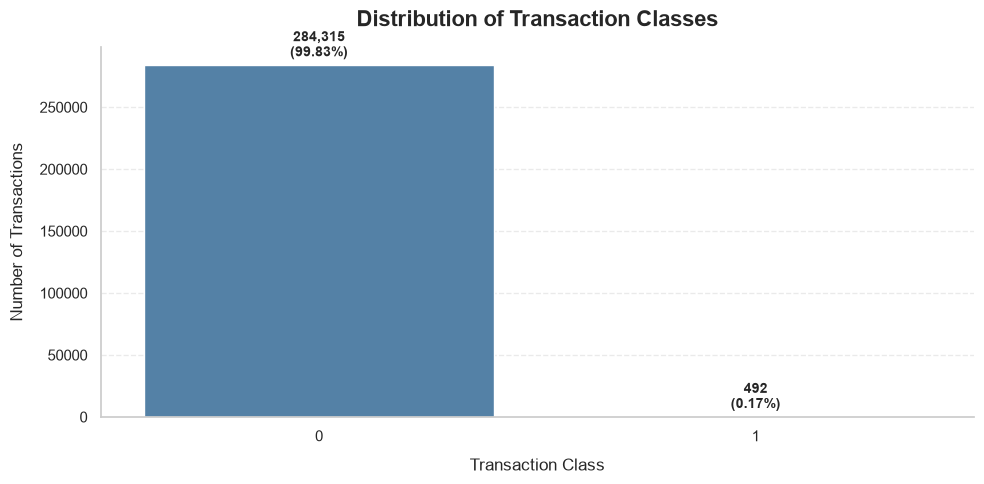

In [48]:
F_barplot(data=df, column='Class')

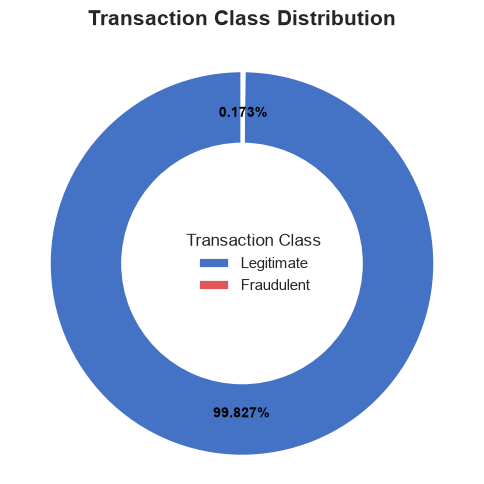

In [49]:
F_Subplot(data=df, column='Class')

#### Transaction Amount Analysis.

This analysis will be particularly important because we have previously identified that "Amount" exhibits a strong positive skew (right-skewed distribution), as well as extreme values.

Our objective is to investigate:
1. How transaction amounts are distributed.
2. Whether there are any extreme values (outliers).
3. Whether there are differences between legitimate and fraudulent transactions.

In [50]:
amount_summary = df['Amount'].describe()
amount_skewness = df['Amount'].skew()
amount_kurtosis = df['Amount'].kurt()

print(f"Transaction Amount Summary:")
print(amount_summary.round(3))
print(f"\nSkewness: {amount_skewness:.4f}")
print(f"Kurtosis: {amount_kurtosis:.4f}")

Transaction Amount Summary:
count    284807.000
mean         88.350
std         250.120
min           0.000
25%           5.600
50%          22.000
75%          77.165
max       25691.160
Name: Amount, dtype: float64

Skewness: 16.9777
Kurtosis: 845.0926


In [51]:
amount_99th_percentile = df['Amount'].quantile(0.99)

print(f"99th percentile: {round(amount_99th_percentile, 2)}")

99th percentile: 1017.97


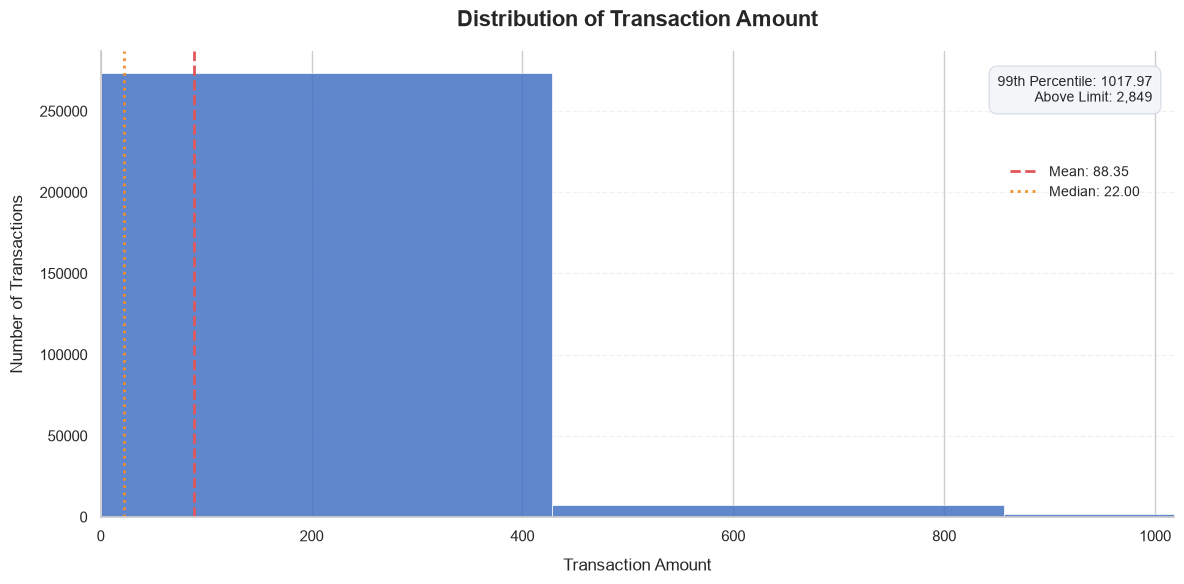

In [52]:
F_histplot(data=df, column='Amount')

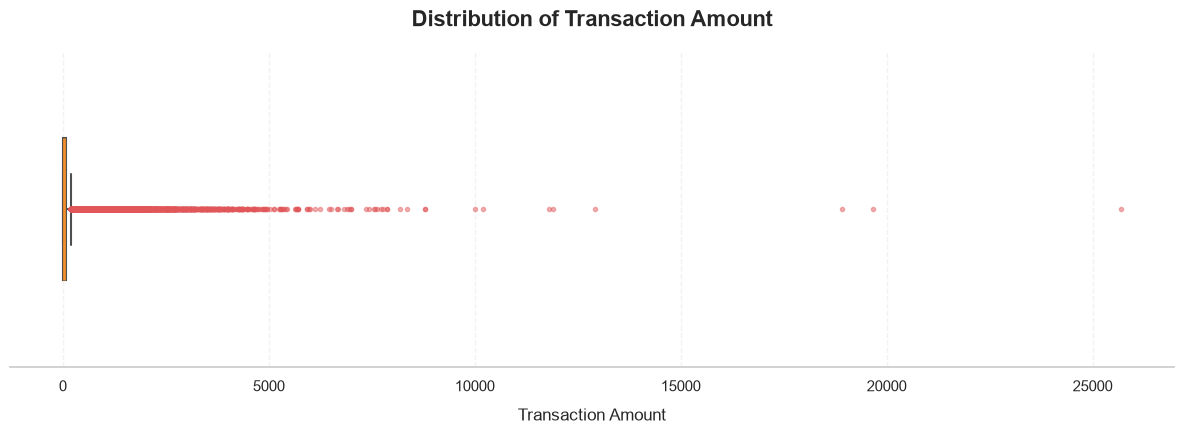

In [53]:
F_boxplot(data=df, column='Amount')

In [54]:
Q1 = df['Amount'].quantile(0.25)
Q3 = df['Amount'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outliers = df[
    (df['Amount'] < lower_bound) |
    (df['Amount'] > upper_bound)
]

print(f"Q1: {Q1:.4f}")
print(f"Q3: {Q3:.4f}")
print(f"IQR: {IQR:.4f}")

print(f"\nLower bound: {lower_bound:.4f}")
print(f"Upper bound: {upper_bound:.4f}")

print(f"\nPotential outliers: {len(outliers):,}")

print(
    f"Outlier percentage: "
    f"{len(outliers) / len(df) * 100:.4f}%"
)

Q1: 5.6000
Q3: 77.1650
IQR: 71.5650

Lower bound: -101.7475
Upper bound: 184.5125

Potential outliers: 31,904
Outlier percentage: 11.2020%


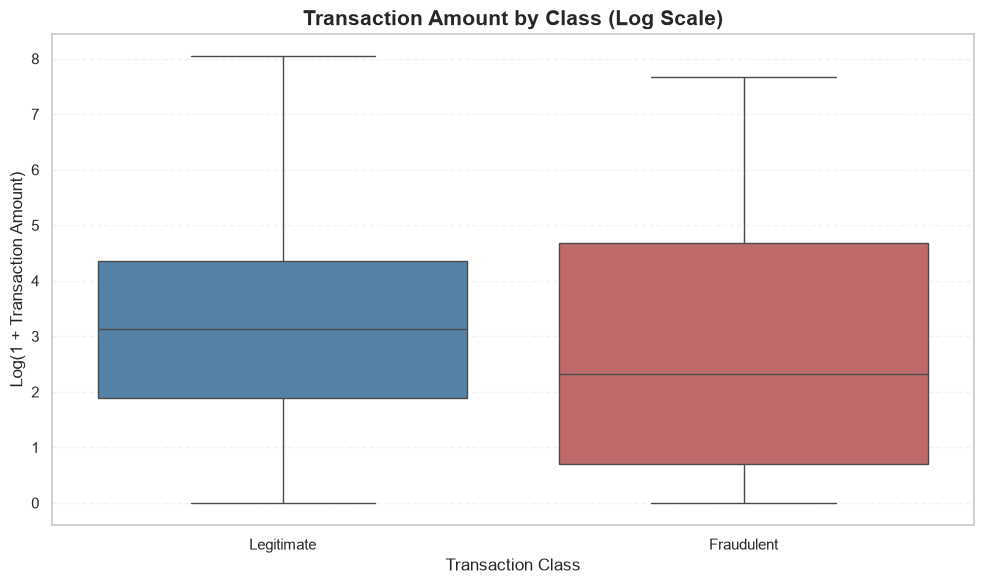

In [55]:
F_barplot_v1(data=df, column=['Amount', 'Class'])

In [56]:
amount_class_comparison = (
    df.groupby('Class')['Amount']
    .agg([
        'count',
        'mean',
        'median',
        'std',
        'min',
        'max'
    ])
)

amount_class_comparison

,count,mean,median,std,min,max
Class,,,,,,
0,284315,88.291022,22.00,250.105092,0.0,25691.16
1,492,122.211321,9.25,256.683288,0.0,2125.87


#### Transaction Time Analysis

This section investigates the temporal characteristics of credit card transactions using the Time variable. The analysis focuses on transaction frequency over time, the statistical distribution of transaction intervals, and potential differences between legitimate and fraudulent transactions.

Histograms, time-based frequency analysis, and boxplots will be used to investigate temporal patterns and support the statistical interpretation.

🎯 The objective is to identify potential differences in transaction timing between the two classes and evaluate the characteristics of the Time variable.

In [57]:
time_df = df[['Time', 'Class']].copy()

time_df['Time_Hours'] = time_df['Time'] / 3600

time_df['Hour_Interval'] = (
    time_df['Time'] // 3600
).astype(int)

time_df.head()

,Time,Class,Time_Hours,Hour_Interval
0,0.0,0,0.000000,0
1,0.0,0,0.000000,0
2,1.0,0,0.000278,0
3,1.0,0,0.000278,0
4,2.0,0,0.000556,0


In [58]:
hourly_transactions = (time_df.groupby('Hour_Interval').size())
hourly_transactions = hourly_transactions.reindex(range(48),fill_value = 0)
hourly_transactions.index.name = 'Hour_Interval'

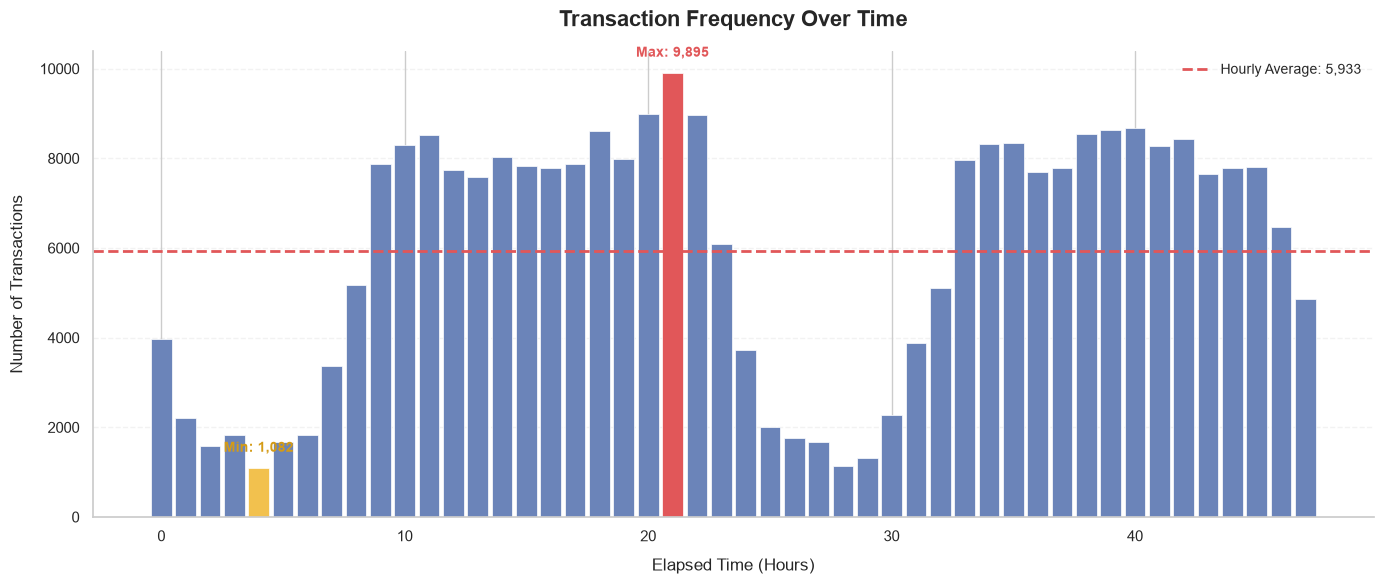

In [59]:
F_barplot_v2(data=hourly_transactions, column=None)

In [60]:
print(f"Average transactions per hour: {hourly_transactions.mean():.2f}")
print(f"Maximum transactions: {hourly_transactions.max():,}")
print(f"Peak activity interval: {hourly_transactions.idxmax()}")
print(f"Minimum transactions: {hourly_transactions.min():,}")
print(f"Lowest activity interval: {hourly_transactions.idxmin()}")

Average transactions per hour: 5933.48
Maximum transactions: 9,895
Peak activity interval: 21
Minimum transactions: 1,082
Lowest activity interval: 4


#### Transaction Time Distribution

This section investigates the statistical distribution of the Time variable.

A histogram and density curve will be used to examine the distribution of elapsed transaction times and identify potential deviations from symmetry.

🎯 The observed distribution will be compared withthe descriptive statistical measures calculated previously.

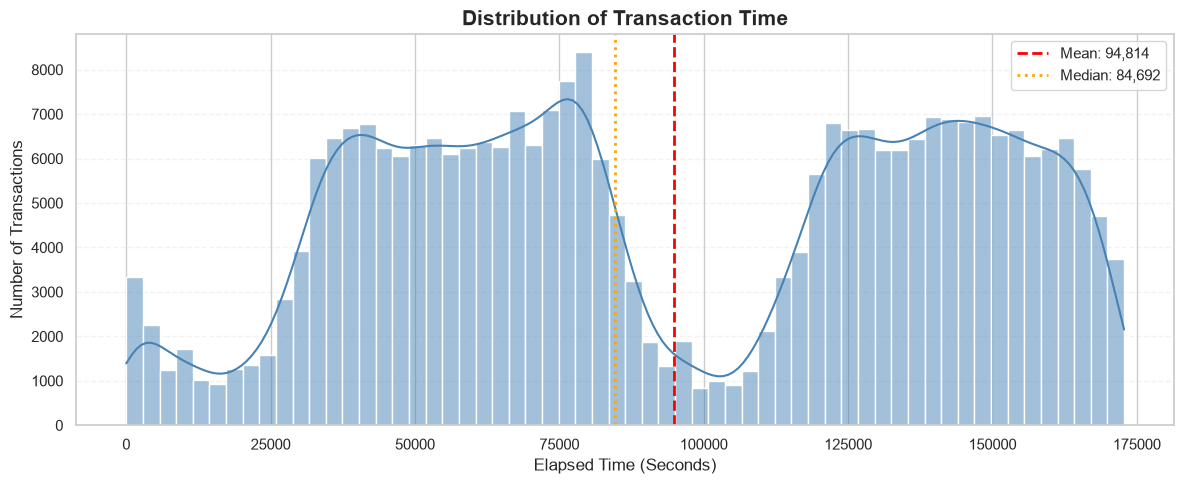

In [61]:
F_histplot_v1(data=df, column="Time")

#### Transaction Time by Class

This section compares the temporal distribution of legitimate and fraudulent transactions.

Boxplots and descriptive statistics are used to investigate differences in transaction timing, central tendency, and variability between the two transaction categories.

🎯 The objective is to identify potential temporal differences between legitimate and fraudulent activities.

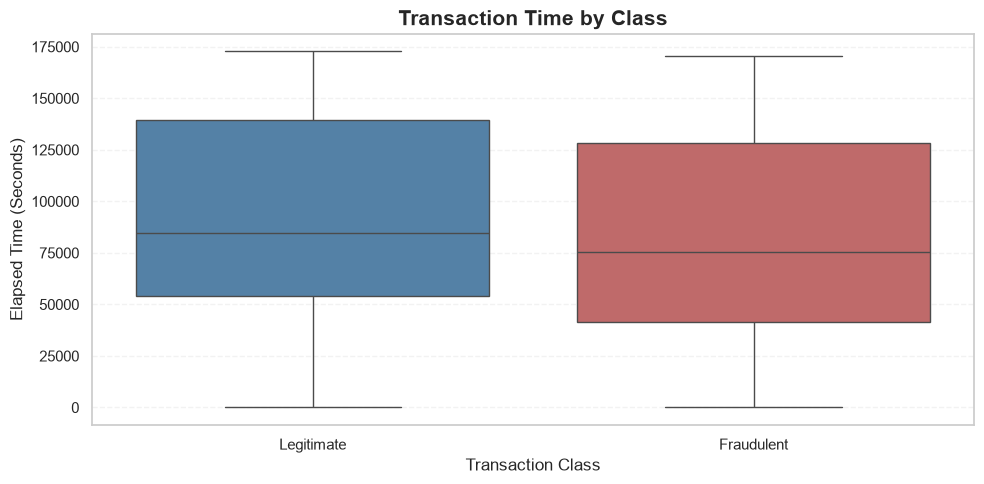

In [62]:
F_barplot_v3(data=df, column=['Time', 'Class'])

In [63]:
df.groupby('Class')['Time'].agg(
    [
        'count',
        'mean',
        'median',
        'std',
        'min',
        'max'
    ])

,count,mean,median,std,min,max
Class,,,,,,
0,284315,94838.202258,84711.0,47484.015786,0.0,172792.0
1,492,80746.806911,75568.5,47835.365138,406.0,170348.0


In [64]:
hourly_class_distribution = (time_df.groupby(['Hour_Interval', 'Class'])
    .size()
    .unstack(fill_value=0)
)

hourly_class_distribution.columns = ['Legitimate', 'Fraudulent']
hourly_class_distribution = (hourly_class_distribution.reindex(range(48), fill_value=0))

hourly_class_distribution['Fraud_Rate'] = (
    hourly_class_distribution['Fraudulent']
    / hourly_class_distribution[
        ['Legitimate', 'Fraudulent']
    ].sum(axis=1)
    * 100
)

2026-11-01 22:44:17,047 | INFO | File_name ~> category.py | Function ~> update | Line ~~> 224  ~~>  Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-01 22:44:17,053 | INFO | File_name ~> category.py | Function ~> update | Line ~~> 224  ~~>  Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


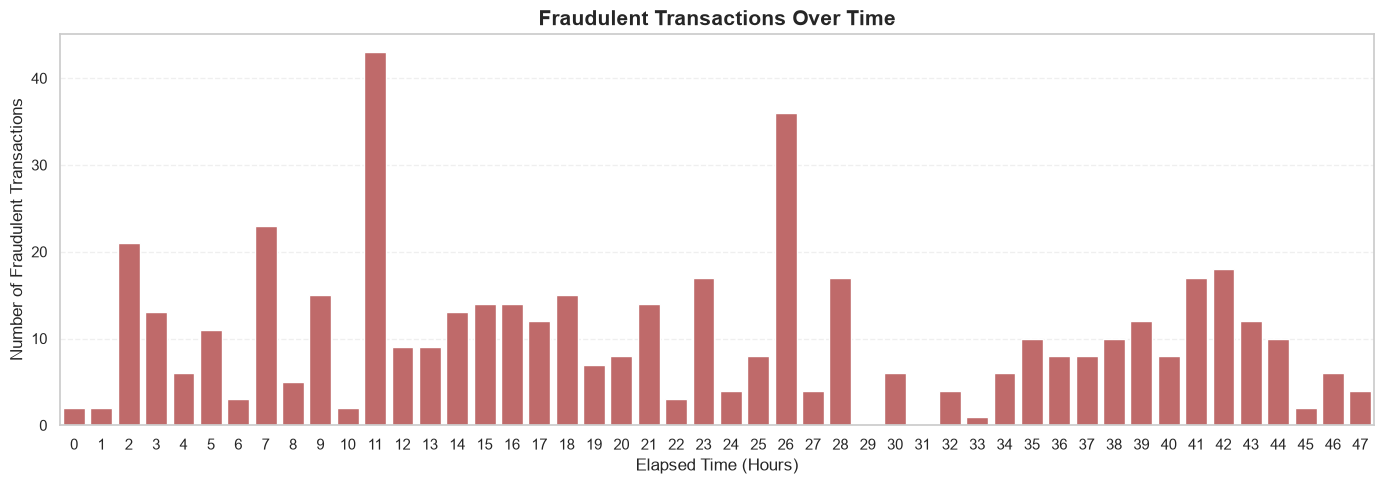

In [65]:
F_barplot_v4(data=hourly_class_distribution, column="Fraudulent")

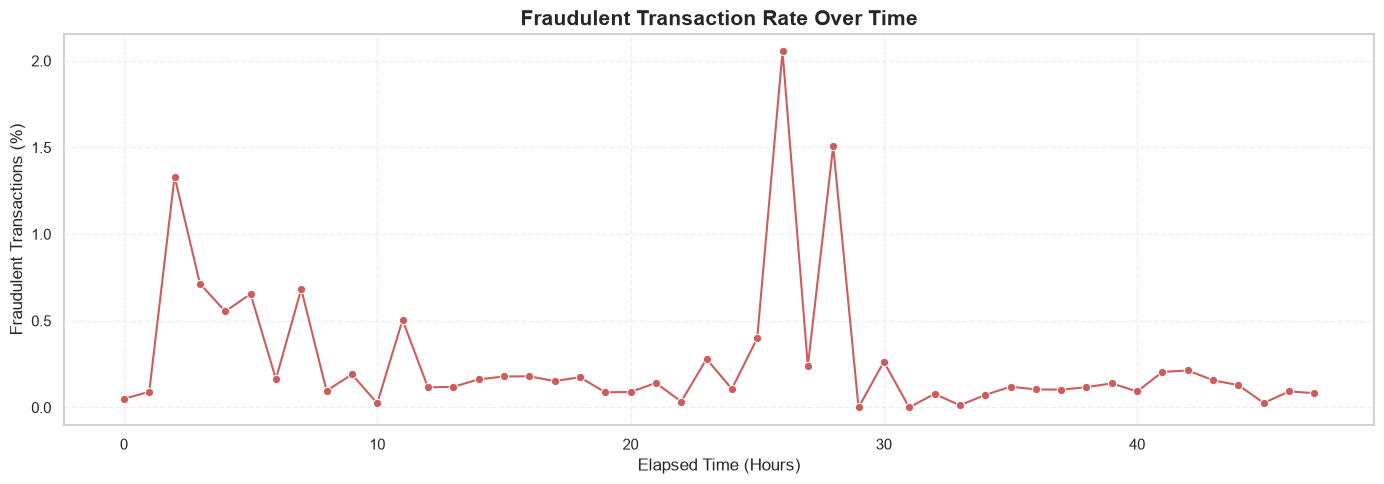

In [66]:
F_lineplot(data=hourly_class_distribution, column="Fraud_Rate")

In [67]:
hourly_summary = hourly_class_distribution[
    ['Legitimate', 'Fraudulent']
].copy()

hourly_summary['Total Transactions'] = (
    hourly_summary['Legitimate']
    + hourly_summary['Fraudulent']
)

hourly_summary['Fraud Rate (%)'] = (
    hourly_summary['Fraudulent']
    / hourly_summary['Total Transactions']
    * 100
)

hourly_summary = hourly_summary.sort_values(
    'Fraud Rate (%)',
    ascending=False
)

hourly_summary.head(10).round(4)

,Legitimate,Fraudulent,Total Transactions,Fraud Rate (%)
Hour_Interval,,,,
26,1716,36,1752,2.0548
28,1110,17,1127,1.5084
2,1555,21,1576,1.3325
3,1808,13,1821,0.7139
7,3345,23,3368,0.6829
5,1670,11,1681,0.6544
4,1076,6,1082,0.5545
11,8474,43,8517,0.5049
25,1995,8,2003,0.3994


#### Feature Distribution Analysis

- This section investigates the statistical characteristics and distributions of the anonymized PCA components (V1–V28).
- Histograms and comparative boxplots will be used to examine feature distributions, variability, and potential differences between legitimate and fraudulent transactions.
- The analysis aims to identify components that exhibit distinct statistical patterns across transaction classes and provide insights into their potential relevance for subsequent classification analysis.
- Since these variables were generated through Principal Component Analysis (PCA), their original meanings are not directly interpretable.

In [68]:
pca_features = [
    f'V{i}' for i in range(1, 29)
]

pca_df = df[pca_features + ['Class']].copy()

pca_df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0


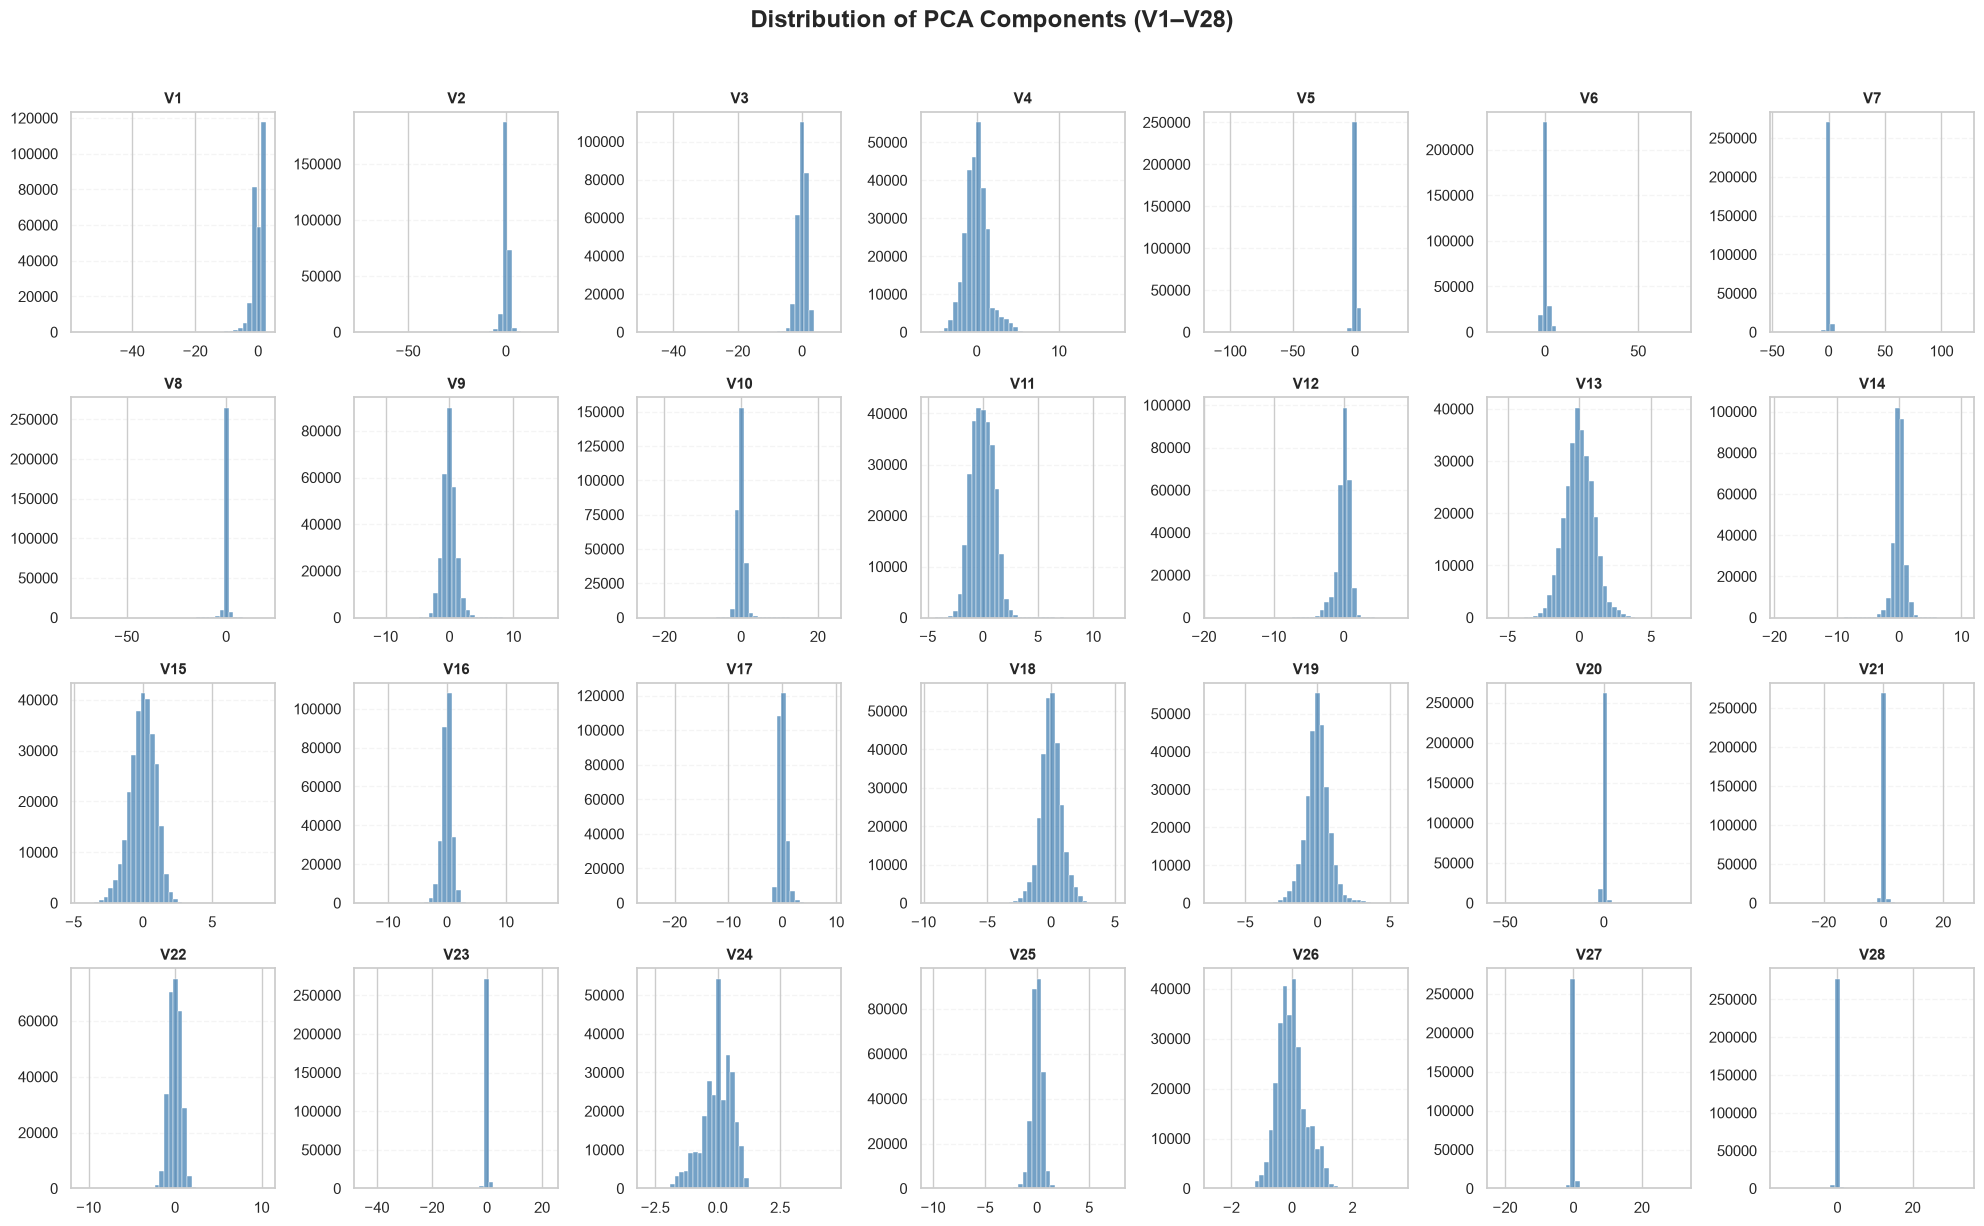

In [69]:
F_histplot_v2(pca_data=pca_df, pca_list=pca_features)

In [70]:
pca_statistics = pd.DataFrame({
    'Mean': pca_df[pca_features].mean(),
    'Std': pca_df[pca_features].std(),
    'Variance': pca_df[pca_features].var(),
    'Skewness': pca_df[pca_features].skew(),
    'Kurtosis': pca_df[pca_features].kurt()
})

pca_statistics

,Mean,Std,Variance,Skewness,Kurtosis
V1,1.175161e-15,1.958696,3.836489,-3.280667,32.486679
V2,3.384974e-16,1.651309,2.726820,-4.624866,95.773106
V3,-1.379537e-15,1.516255,2.299029,-2.240155,26.619551
V4,2.094852e-15,1.415869,2.004684,0.676292,2.635455
V5,1.021879e-15,1.380247,1.905081,-2.425901,206.904560
V6,1.494498e-15,1.332271,1.774946,1.826581,42.642494
V7,-5.620335e-16,1.237094,1.530401,2.553907,405.607417
V8,1.149614e-16,1.194353,1.426479,-8.521944,220.586974
V9,-2.414189e-15,1.098632,1.206992,0.554680,3.731311
V10,2.238554e-15,1.088850,1.185594,1.187141,31.988239


Feature variability

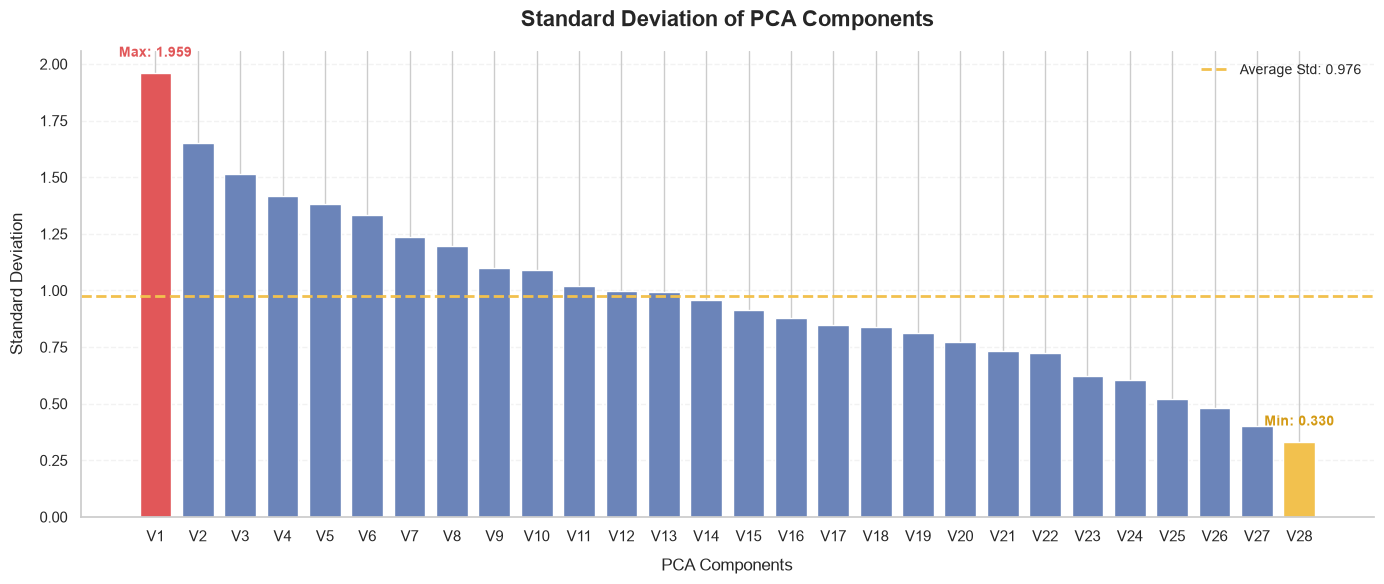

In [71]:
F_barplot_v5(pca_data=pca_df, pca_list=pca_features)

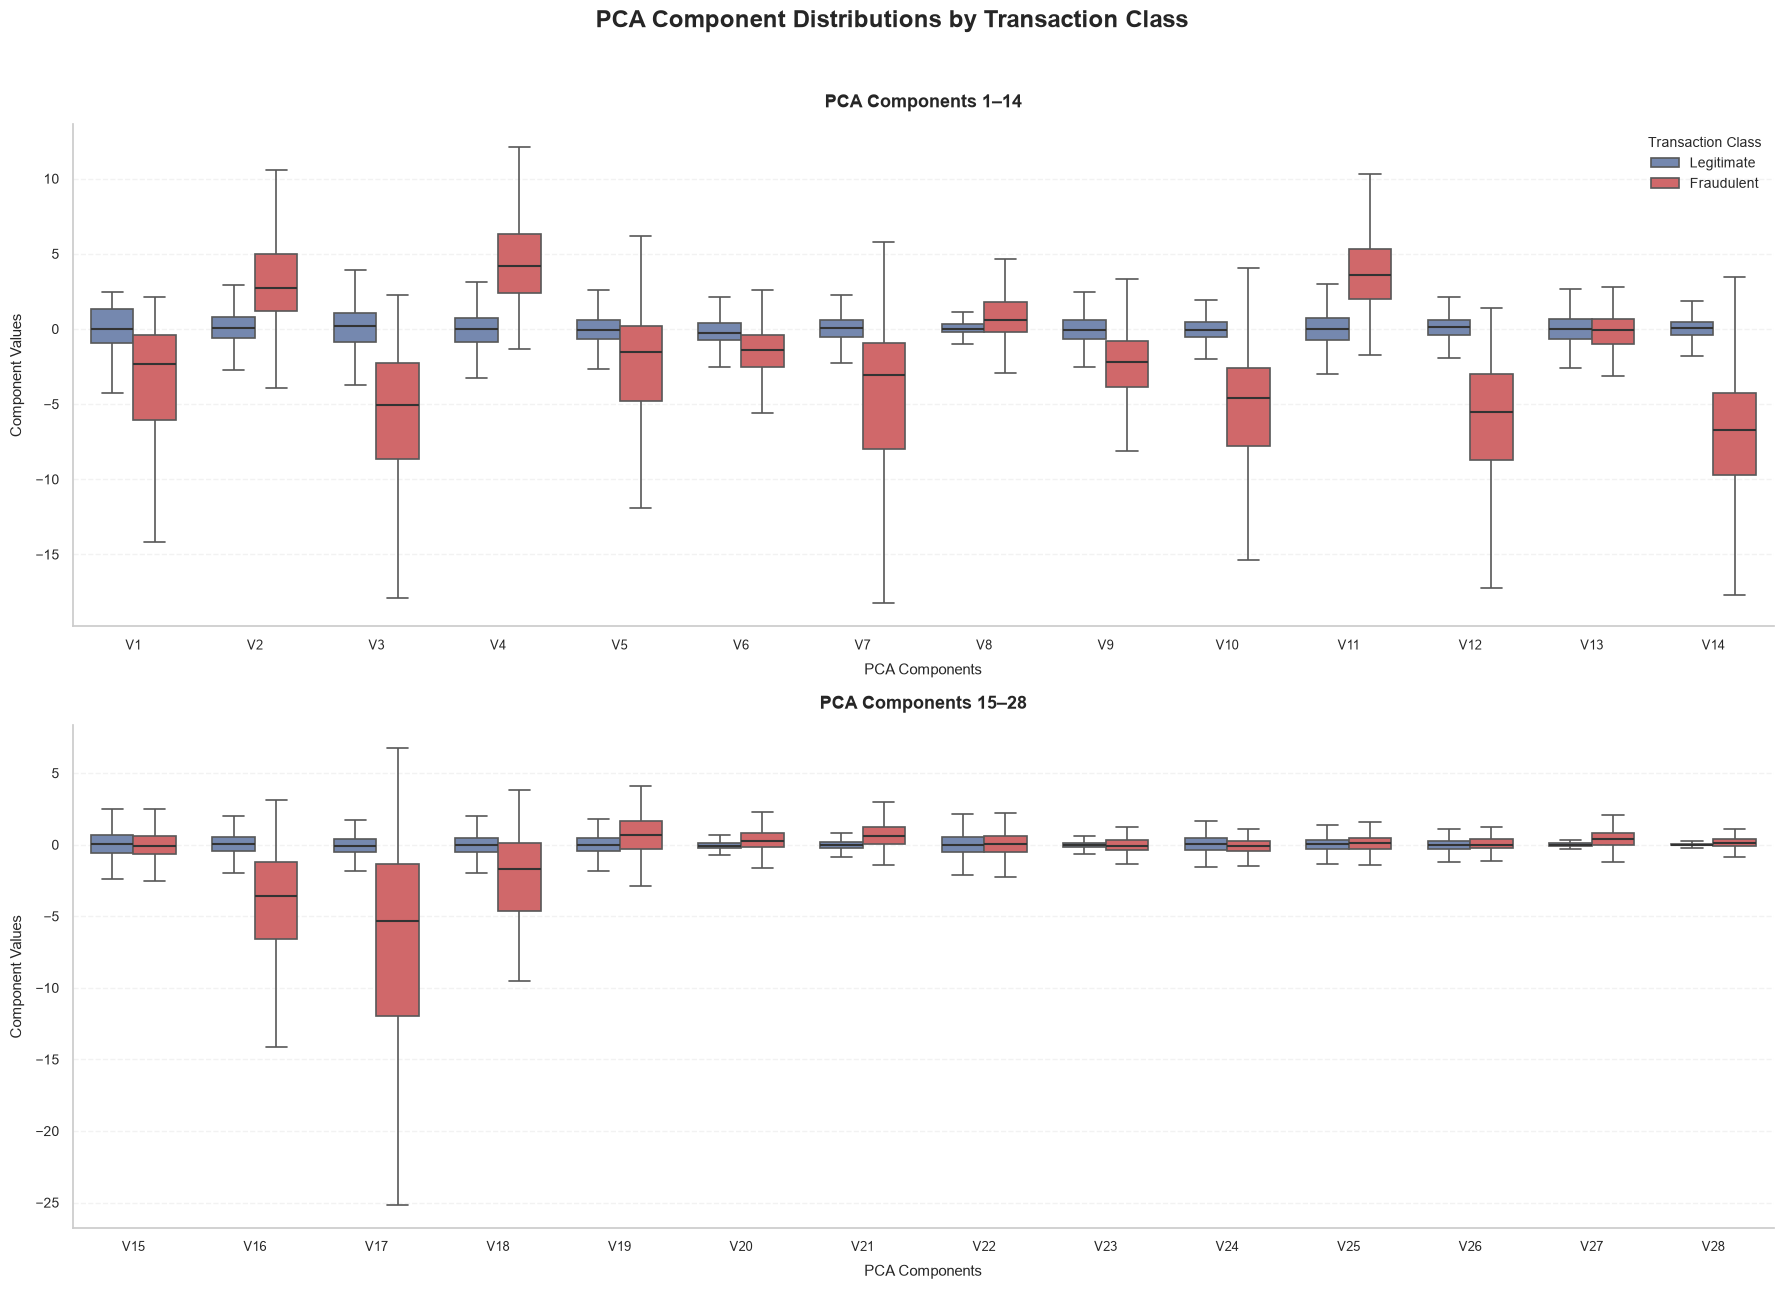

In [72]:
F_boxplot_v1(pca_data=pca_df, pca_list=pca_features)

In [73]:
pca_class_comparison = (
    pca_df.groupby('Class')[pca_features]
    .agg(['median', 'std'])
)

pca_class_comparison

V1                  V2                  V3                  V4  \
         median       std    median       std    median       std    median   
Class                                                                         
0      0.020023  1.929814  0.064070  1.636146  0.182158  1.459429 -0.022405   
1     -2.342497  6.783687  2.717869  4.291216 -5.075257  7.110937  4.177147   

                       V5            ...       V24                 V25  \
            std    median       std  ...    median       std    median   
Class                                ...                                 
0      1.399333 -0.053457  1.356952  ...  0.041082  0.605776  0.016417   
1      2.873318 -1.522962  5.372468  ... -0.060795  0.515577  0.088371   

                      V26                 V27                 V28            
            std    median       std    median       std    median       std  
Class                                                                        
0      0.520673 -0.052227  0.482241  0.001230  0.399847  0.011199  0.329570  
1      0.797205  0.004321  0.471679  0.394926  1.376766  0.146344  0.547291  

[2 rows x 56 columns]

In [74]:
legitimate_median = (pca_df[pca_df['Class'] == 0][pca_features].median())
fraudulent_median = (pca_df[pca_df['Class'] == 1][pca_features].median())
median_comparison = pd.DataFrame({
    'Legitimate Median': legitimate_median,
    'Fraudulent Median': fraudulent_median})

median_comparison['Absolute Difference'] = (median_comparison['Fraudulent Median'] - median_comparison['Legitimate Median']).abs()
median_comparison = median_comparison.sort_values('Absolute Difference', ascending=False)

median_comparison

,Legitimate Median,Fraudulent Median,Absolute Difference
V14,0.051947,-6.729720,6.781667
V12,0.141679,-5.502530,5.644208
V3,0.182158,-5.075257,5.257415
V17,-0.064833,-5.302949,5.238115
V10,-0.091872,-4.578825,4.486953
V4,-0.022405,4.177147,4.199552
V11,-0.034923,3.586218,3.621142
V16,0.067377,-3.549795,3.617172
V7,0.041138,-3.034402,3.075540
V2,0.064070,2.717869,2.653799


In [75]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

statistical_results = []

for feature in pca_features:

    legitimate = pca_df.loc[pca_df['Class'] == 0, feature]
    fraudulent = pca_df.loc[pca_df['Class'] == 1, feature]

    statistic, p_value = mannwhitneyu(fraudulent, legitimate, alternative='two-sided')

    effect_size = (
        (2 * statistic) /
        (len(fraudulent) * len(legitimate))
    ) - 1

    statistical_results.append(
        {
            'Feature': feature,
            'U Statistic': statistic,
            'P Value': p_value,
            'Effect Size': effect_size
        })

statistical_results = pd.DataFrame(statistical_results)

statistical_results['Adjusted P Value'] = (
    multipletests(
        statistical_results['P Value'],
        method='fdr_bh'
    )[1]
)

statistical_results = (statistical_results.sort_values('Adjusted P Value').reset_index(drop=True))
statistical_results

,Feature,U Statistic,P Value,Effect Size,Adjusted P Value
0,V14,7111691.0,1.471581e-260,-0.898319,4.120426e-259
1,V4,131246382.0,3.625904e-248,0.876517,5.076266e-247
2,V12,8806982.0,8.416027e-247,-0.874081,7.854958e-246
3,V11,128424209.0,4.910592e-226,0.836166,3.437414e-225
4,V10,12021914.0,9.611131e-222,-0.828115,5.382233e-221
5,V3,12299525.0,1.211048e-219,-0.824146,5.651558e-219
6,V2,119593684.0,1.650438e-163,0.709910,6.601751e-163
7,V16,21383707.0,1.808172e-156,-0.694263,6.328603e-156
8,V9,21809136.0,8.943723e-154,-0.688180,2.782492e-153
9,V7,22967158.0,1.464234e-146,-0.671623,4.099854e-146


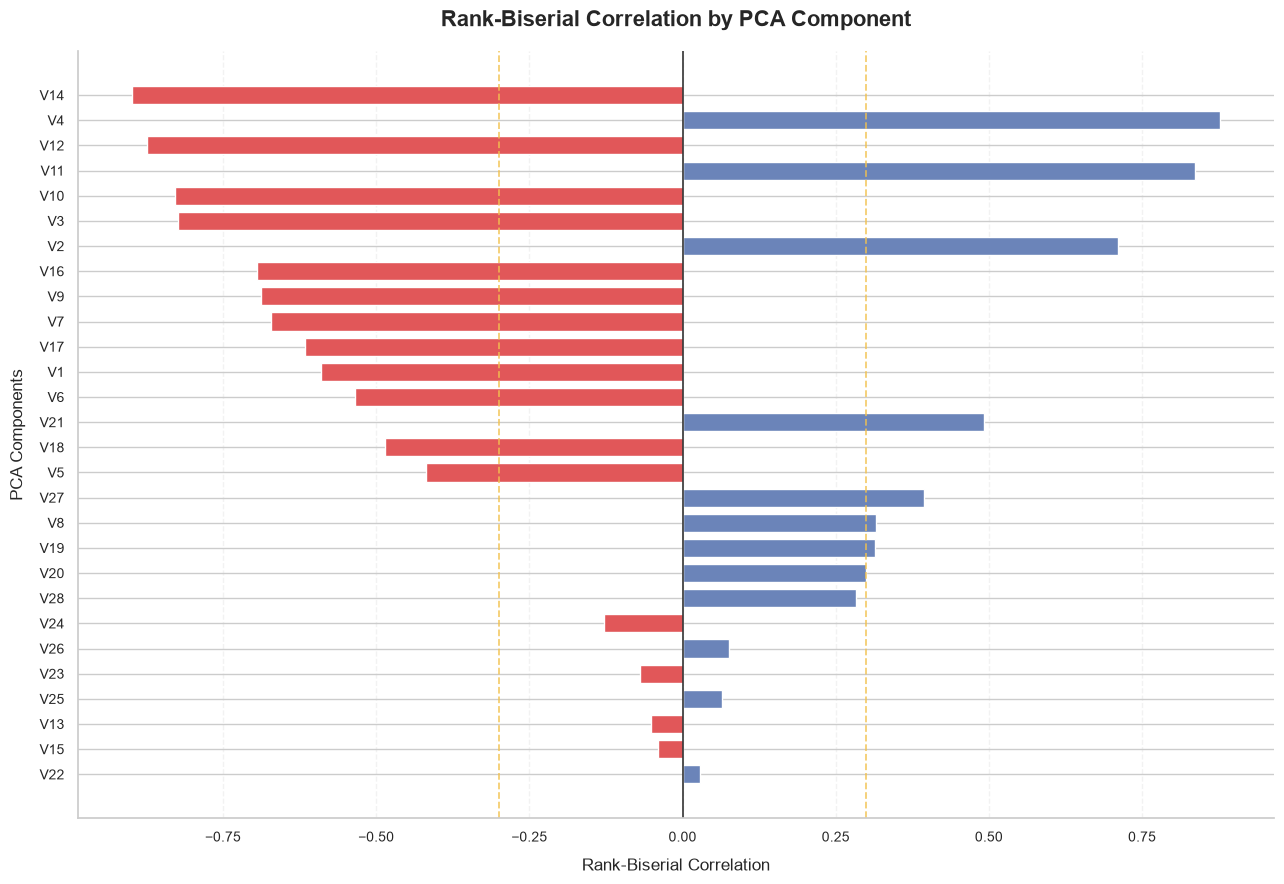

In [76]:
F_barh(statistical_data = statistical_results)

#### Statistical Significance and Effect Size Analysis


The Mann–Whitney U test was applied to investigate differences in the distributions of the 28 PCA components between legitimate and fraudulent transactions.

To account for multiple hypothesis testing, the Benjamini-Hochberg procedure was applied using a false discovery rate of 5%.

The results indicated statistically significant differences in 25 out of the 28 components. `V13`, `V15`, and `V22` did not reach statistical significance after multiple-testing correction.

The effect size analysis, based on rank-biserial correlation, revealed particularly strong distributional separation for `V14 (-0.8983), V4 (0.8765), V12 (-0.8741), V11 (0.8362), and V10 (-0.8281).`

The direction of the effect indicates whether fraudulent transactions tend to exhibit higher or lower values compared with legitimate transactions.

These findings are consistent with the descriptive analysis and comparative boxplots, providing additional statistical evidence of differences between the transaction classes.

However, statistical significance and effect size should not be interpreted as direct measures of predictive performance. The actual contribution of these components to fraud detection must be evaluated through classification models and appropriate validation procedures.

### 👨🏾‍🔬 Probability Distributions

⚠⚠⚠ Warning ⚠⚠⚠

The `cleaned dataset` has been selected as the primary data source for the statistical distribution analysis. This decision ensures consistency between the exploratory data analysis, statistical calculations, and subsequent machine learning stages. By using the cleaned dataset, the probability estimates and statistical parameters are calculated from the same observations retained for the project. The dataset contains 283,726 transactions, including 473 fraudulent transactions and 283,253 legitimate transactions.

⚠⚠⚠ For the next stages, we will use `25,000` stratified samples, maintaining the original distribution of the `Class` variable. ⚠⚠⚠

In [77]:
from sklearn.model_selection import train_test_split

_cleaned_df, _ = train_test_split(
    cleaned_df,
    train_size=25_000,
    stratify=cleaned_df['Class'],
    random_state=42
)

_cleaned_df = _cleaned_df.reset_index(drop=True)

In [78]:
print(_cleaned_df['Class'].value_counts())
print(_cleaned_df['Class'].value_counts(normalize=True) * 100)

Class
0    24958
1       42
Name: count, dtype: int64
Class
0    99.832
1     0.168
Name: proportion, dtype: float64


In [79]:
len(_cleaned_df)

25000

In [80]:
len(cleaned_df)

283726

#### 🔬 Binomial Distribution

The Binomial Distribution is used to model the probability of obtaining a specific number of successes within a fixed number of independent trials (Pennsylvania State University, n.d.).

In this project, the distribution is applied to credit card fraud detection, where each transaction has two possible outcomes:

* **Success (1):** Fraudulent transaction.
* **Failure (0):** Legitimate transaction.

The objective is to estimate the probability of fraudulent transactions and investigate the likelihood of observing different numbers of fraudulent events within a fixed sample of transactions.

The analysis uses the cleaned dataset, containing `25,000` observations, including `42` fraudulent transactions and `24,958` legitimate transactions.

The probability function is:

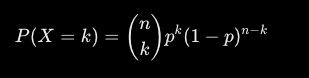

The probability mass function calculates the probability of observing exactly (k) successes in (n) independent trials, where (p) represents the probability of success in each trial (Pennsylvania State University, n.d.; SciPy, n.d.-a).

**Parameter**
- n ~~> Number of independent trials
- k	~~> Number of successful outcomes
- p	~~> Probability of success
- 1-p ~~> Probability of failure
- P(X=k) ~~> Probability of exactly k successes

On project:
- n ~~> Number of transactions analyzed.
- k ~~> Number of fraudulent transactions.
- p ~~> Probability of a transaction being fraudulent.

The Binomial distribution assumes that each observation has two possible outcomes, that the trials are independent, and that the probability of success remains constant across all trials (Pennsylvania State University, n.d.).

We need to consider these assumptions when interpreting the results, especially since financial transactions may exhibit temporal or behavioral dependencies.

⚠⚠ Warning ⚠⚠

We willl use exclusively the `cleaned_df` as the primary reference. ( Dataset with no duplicates )

In this step, we will apply probability concepts to the problem of fraud detection, investigating the likelihood of encountering fraudulent transactions within a set of operations.

In [81]:
print(f"Total observations: {len(_cleaned_df):,}")
print(f"Legitimate transactions: {(_cleaned_df['Class'] == 0).sum():,}")
print(f"Fraudulent transactions: {(_cleaned_df['Class'] == 1).sum():,}")
print(f"Remaining duplicates: {_cleaned_df.duplicated().sum():,}")

Total observations: 25,000
Legitimate transactions: 24,958
Fraudulent transactions: 42
Remaining duplicates: 0


In [82]:
total_transactions = len(cleaned_df)

fraud_count = (cleaned_df['Class'].eq(1).sum())
legitimate_count = (cleaned_df['Class'].eq(0).sum())

p_fraud = fraud_count / total_transactions
p_legitimate = legitimate_count / total_transactions

print(f"Fraud probability: {p_fraud:.8f}")
print(f"Legitimate probability: {p_legitimate:.8f}")

print(f"Fraud percentage: {p_fraud * 100:.4f}%")
print(f"Legitimate percentage: {p_legitimate * 100:.4f}%")

Fraud probability: 0.00166710
Legitimate probability: 0.99833290
Fraud percentage: 0.1667%
Legitimate percentage: 99.8333%


In [83]:
n = 25_000
p = p_fraud

expected_value = n * p
variance       = n * p * (1 - p)
std_deviation  = np.sqrt(variance)

print(f"Number of trials: {n:,}")
print(f"Fraud probability: {p:.8f}")

print(f"Expected fraudulent transactions: {expected_value:.4f}")
print(f"Binomial variance: {variance:.4f}")
print(f"Standard deviation: {std_deviation:.4f}")

Number of trials: 25,000
Fraud probability: 0.00166710
Expected fraudulent transactions: 41.6775
Binomial variance: 41.6081
Standard deviation: 6.4504


In [109]:
from scipy.stats import binom

prob_zero = binom.pmf(0, n, p)
prob_one = binom.pmf(1, n, p)
prob_two = binom.pmf(2, n, p)

prob_at_least_one = binom.sf(0, n, p)

print(f"P(X = 0) ~ No fraudulent transactions: ~~> {prob_zero * 100:.8e}%")
print(f"P(X = 1) ~ Exactly one fraudulent transaction: ~~> {prob_one:.8e}%")
print(f"P(X = 2) ~ Exactly two fraudulent transactions: ~~> {prob_two:.8e}%")
print(f"P(X >= 1) ~ At least one fraudulent transaction: ~~> {prob_at_least_one * 100:.2f}%")

P(X = 0) ~ No fraudulent transactions: ~~> 7.66606781e-17%
P(X = 1) ~ Exactly one fraudulent transaction: ~~> 3.20036335e-17%
P(X = 2) ~ Exactly two fraudulent transactions: ~~> 6.68003212e-16%
P(X >= 1) ~ At least one fraudulent transaction: ~~> 100.00%


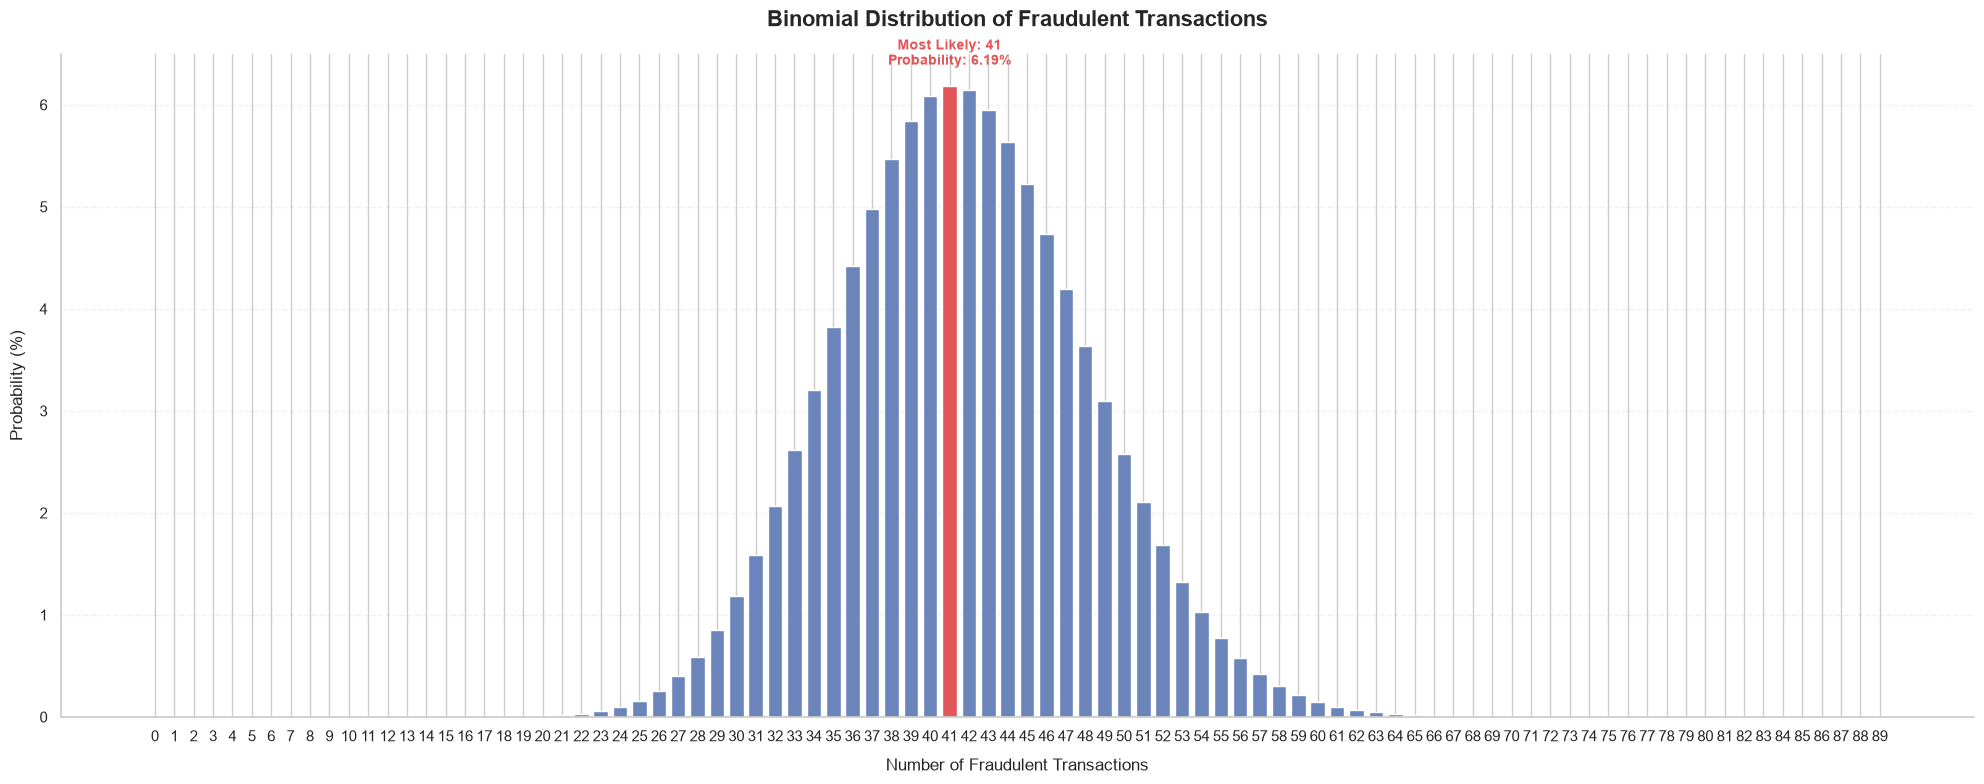

In [85]:
F_barplot_v6()

##### 👨🏾‍🏫 Interpretation of Binomial Distribution

The Binomial Distribution was applied to investigate the probability of fraudulent transactions within a fixed number of credit card operations.

Based on the complete cleaned dataset, the estimated probability of a fraudulent transaction was approximately `0.1667%`, while the probability of a legitimate transaction was approximately `99.8333%`.

Using a sample size of `25,000` independent transactions, the expected number of fraudulent transactions was approximately `41.68`, with a variance of `41.61` and a standard deviation of `6.45`.

The probability distribution indicates that observing `41` fraudulent transactions is the most likely individual outcome, with an approximate probability of `6.19%`. The graph shows that the probabilities are concentrated around the expected number of fraudulent transactions, with lower probabilities for outcomes further away from this central value.

Furthermore, the probability of observing at least one fraudulent transaction is practically `100%`, while the probability of observing no fraudulent transactions is extremely small.

These findings demonstrate that, although the individual probability of fraud is relatively low, the expected number of fraudulent transactions increases when a larger number of operations is considered.

The Binomial Distribution therefore provides a useful mathematical framework for estimating fraudulent occurrences within a fixed sample size.

However, its assumptions of independent trials and constant probability should be considered when interpreting the results, as real-world financial transactions may exhibit temporal or behavioral dependencies.

#### 🔬 Poisson Distribution

The Poisson Distribution is a discrete probability distribution used to model the number of events occurring within a fixed interval, assuming that events occur independently and at a constant average rate.

The analysis initially focuses on the relationship between the Binomial and Poisson distributions. Since the probability of an individual transaction being fraudulent is relatively small, the Poisson Distribution can provide an approximation of the Binomial model under appropriate conditions.

The objective is to calculate the expected event rate, estimate the probabilities of different numbers of fraudulent transactions, and compare theoretical results obtained from both distributions.

The analysis uses the cleaned dataset, containing `25,000` observations, including `42` fraudulent transactions and `24,958` legitimate transactions.

Its probability function is:

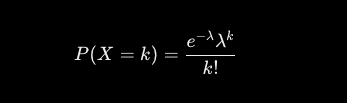

Where:
- k: number of events.
- λ: Expected number of events.
- e: Euler's number
- (P(X=k): Probability of exactly k events

In [86]:
from scipy.stats import poisson

lambda_poisson   = n * p
poisson_mean     = lambda_poisson
poisson_variance = lambda_poisson

poisson_std = np.sqrt(poisson_variance)

print(f"Poisson Lambda: {lambda_poisson:.4f}")
print(f"Expected value: {poisson_mean:.4f}")
print(f"Variance: {poisson_variance:.4f}")
print(f"Standard deviation: {poisson_std:.4f}")

Poisson Lambda: 41.6775
Expected value: 41.6775
Variance: 41.6775
Standard deviation: 6.4558


In [104]:
prob_zero_poisson = poisson.pmf(0, lambda_poisson)
prob_one_poisson = poisson.pmf(1, lambda_poisson)
prob_two_poisson = poisson.pmf(2, lambda_poisson)
prob_at_least_one_poisson = poisson.sf(0, lambda_poisson)

print(f"P(X = 0) ~~> No fraudulent transactions: ~~> {prob_zero_poisson:.8e}%")
print(f"P(X = 1) ~~> Exactly one fraudulent transaction ~~> {prob_one_poisson:.8e}%")
print(f"P(X = 2) ~~> Exactly two fraudulent transactions ~~> {prob_two_poisson:.8e}%")
print(f"P(X >= 1) ~~> At least one fraudulent transaction ~~> {prob_at_least_one_poisson * 100:.2f}%")

P(X = 0) ~~> No fraudulent transactions: ~~> 7.93737652e-19%
P(X = 1) ~~> Exactly one fraudulent transaction ~~> 3.30810280e-17%
P(X = 2) ~~> Exactly two fraudulent transactions ~~> 6.89367833e-16%
P(X >= 1) ~~> At least one fraudulent transaction ~~> 100.00%


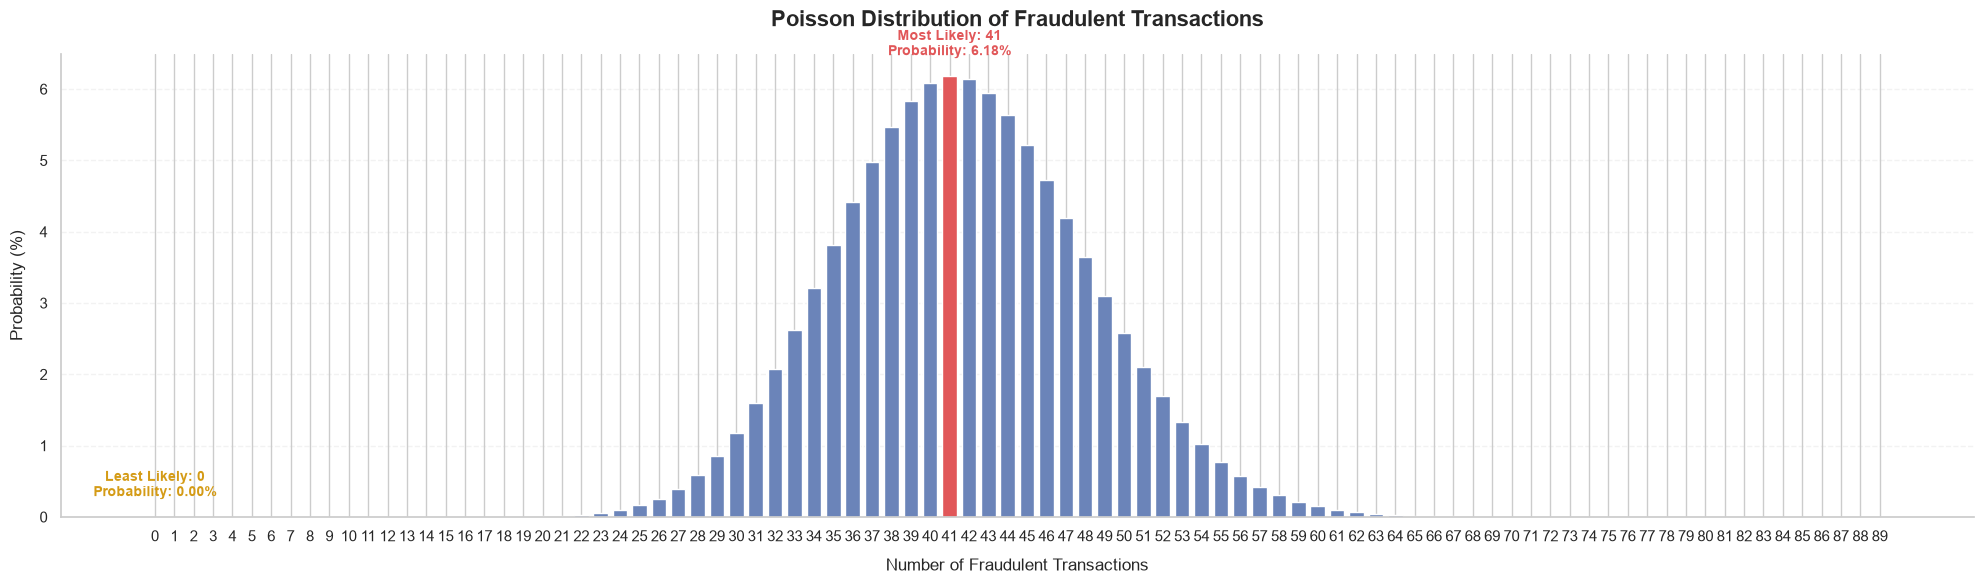

In [88]:
F_barplot_v7()

In [89]:
x = np.arange(0, 90)

binomial_probabilities = binom.pmf(x, n, p)
poisson_probabilities = poisson.pmf(x,lambda_poisson)

distribution_comparison = pd.DataFrame({
    'Fraud Count': x,
    'Binomial Probability': binomial_probabilities,
    'Poisson Probability': poisson_probabilities
})

distribution_comparison['Absolute Difference'] = (
    distribution_comparison['Binomial Probability']
    - distribution_comparison['Poisson Probability']
).abs()

distribution_comparison['Difference (%)'] = (
    distribution_comparison['Absolute Difference'] * 100
)

distribution_comparison

,Fraud Count,Binomial Probability,Poisson Probability,Absolute Difference,Difference (%)
0,0,7.666068e-19,7.937377e-19,2.713087e-20,2.713087e-18
1,1,3.200363e-17,3.308103e-17,1.077395e-18,1.077395e-16
2,2,6.680032e-16,6.893678e-16,2.136462e-17,2.136462e-15
3,3,9.294995e-15,9.577050e-15,2.820550e-16,2.820550e-14
4,4,9.699821e-14,9.978696e-14,2.788755e-15,2.788755e-13
...,...,...,...,...,...
85,85,1.336430e-09,1.385305e-09,4.887477e-11,4.887477e-09
86,86,6.465397e-10,6.713498e-10,2.481002e-11,2.481002e-09
87,87,3.091762e-10,3.216115e-10,1.243532e-11,1.243532e-09
88,88,1.461625e-10,1.523179e-10,6.155377e-12,6.155377e-10


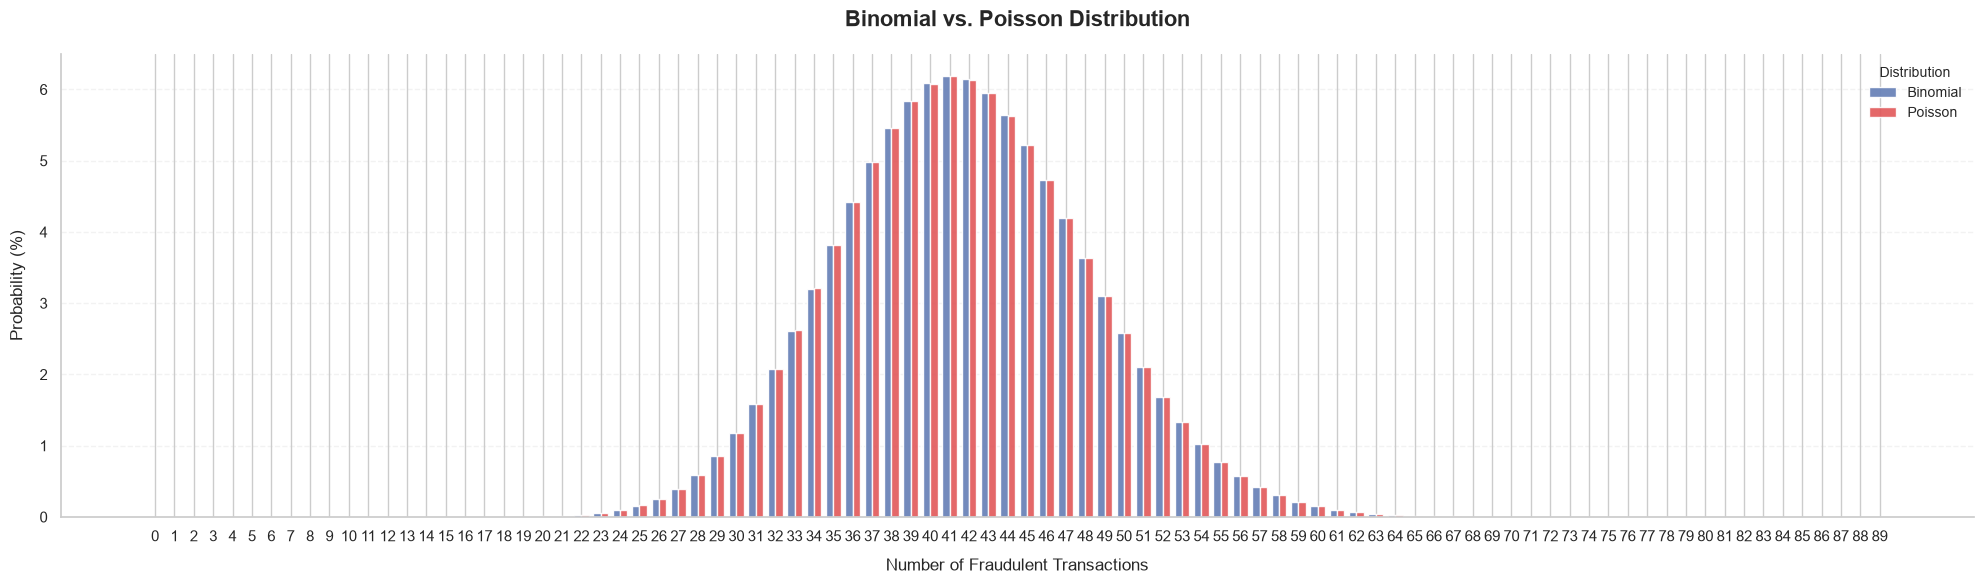

In [90]:
F_barplot_v8()

In [91]:
max_difference = (distribution_comparison['Absolute Difference'].max())
mean_difference = (distribution_comparison['Absolute Difference'].mean())

print(f"Maximum absolute difference: {max_difference:.8f}")
print(f"Mean absolute difference: {mean_difference:.8f}")

Maximum absolute difference: 0.00005148
Mean absolute difference: 0.00000899


##### 👨🏾‍🏫 Interpretation of Poisson Distribution

The Poisson Distribution was applied to model the occurrence of fraudulent transactions within a sample of `25,000` credit card operations.

Based on the estimated fraud probability obtained from the complete cleaned dataset, the expected number of fraudulent transactions was calculated using the parameter `λ = np`, resulting in approximately `41.6775`.

The resulting Poisson model presented an expected value and variance of approximately `41.6775`, with a standard deviation of `6.4558`. These results indicate that the number of fraudulent transactions is expected to fluctuate around 42 within samples of this size.

The probability distribution identifies `41` fraudulent transactions as the most likely individual outcome, with an approximate probability of `6.18%`. The graph illustrates that probabilities are concentrated around this central value, gradually decreasing for outcomes further away from the expected number of fraudulent transactions.

Furthermore, the probability of observing at least one fraudulent transaction is practically `100%`, while the probability of observing no fraudulent transactions is extremely small.

A comparison between the Binomial and Poisson distributions was performed for fraud counts ranging from `0` to `89`. The maximum absolute probability difference was approximately `0.00005148`, while the mean absolute difference was approximately `0.00000899`.

These results demonstrate a close agreement between the two distributions under the selected parameters. This supports the use of the Poisson Distribution as an approximation of the Binomial Distribution when the number of trials is large and the probability of an individual event is small.

However, this approximation relies on assumptions of independent events and a constant probability of occurrence. These conditions should be considered when interpreting the results, as real-world financial transactions may exhibit temporal or behavioral dependencies.

#### 🔬 Normal Distribution

The Normal Distribution, also known as the Gaussian Distribution, is a continuous probability distribution characterized by a symmetric, bell-shaped curve centered around its mean.

In this project, the Normal Distribution is investigated to understand the statistical behavior of numerical variables within the credit card fraud dataset.

The analysis focuses on transaction amounts, elapsed transaction time, and selected PCA components. Their distributions are examined using descriptive statistics, histograms, density curves, Q-Q plots, and statistical normality tests.

Additionally, legitimate and fraudulent transactions are compared to investigate whether their distributions exhibit different characteristics.

The objective is to identify deviations from normality, evaluate distribution shapes, and understand how these characteristics influence the statistical interpretation of the datas.

The density function of the Normal distribution is:

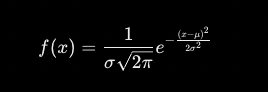

Where:
- x: Observed value.
- μ: Population mean.
- σ: Population standard deviation.
- σ2: Population variance.
- π: Mathematical constant

Based on the `PCA Component Distributions by Transaction Class` chart, we will select the following variables:

In [92]:
normal_features = ['Amount', 'Time', 'V14', 'V4', 'V12']

normal_df = _cleaned_df[normal_features + ['Class']].copy()

normal_df.head()

,Amount,Time,V14,V4,V12,Class
0,32.01,169091.0,-0.284836,-0.485538,-0.930240,0
1,1.00,128986.0,0.564089,0.581525,0.490862,0
2,49.99,135607.0,0.418381,-1.122114,-0.069225,0
3,15.77,155846.0,-0.814216,-0.784715,0.690140,0
4,26.15,159813.0,-0.312238,-0.247939,-0.383299,0


In [93]:
normal_statistics = pd.DataFrame({
    'Mean': normal_df[normal_features].mean(),
    'Median': normal_df[normal_features].median(),
    'Std': normal_df[normal_features].std(),
    'Skewness': normal_df[normal_features].skew(),
    'Kurtosis': normal_df[normal_features].kurt()
})

normal_statistics

,Mean,Median,Std,Skewness,Kurtosis
Amount,88.903010,21.460000,256.013924,10.978092,193.710175
Time,94904.277600,84871.000000,47396.924723,-0.035985,-1.291629
V14,0.000959,0.054185,0.951763,-1.742221,19.754516
V4,0.022351,0.003459,1.436526,0.727076,2.913237
V12,0.000754,0.141739,0.991886,-2.041466,16.114117


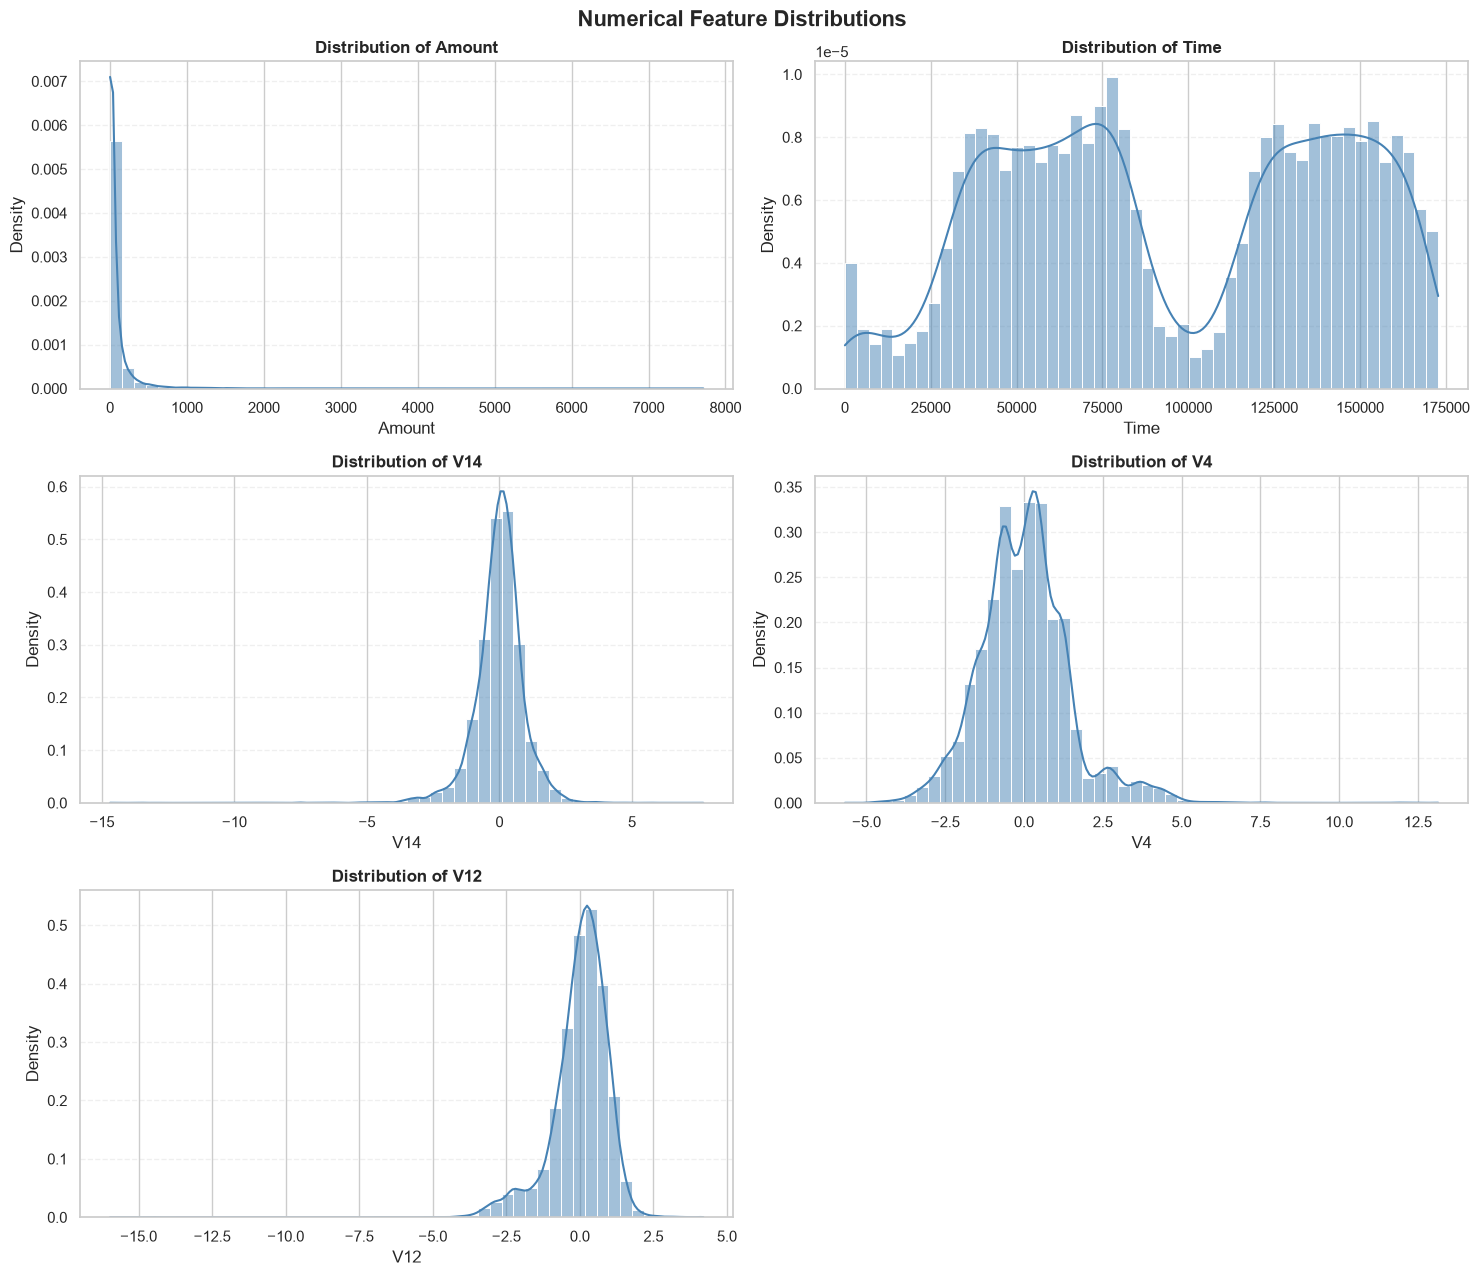

In [94]:
F_histplot_v3()

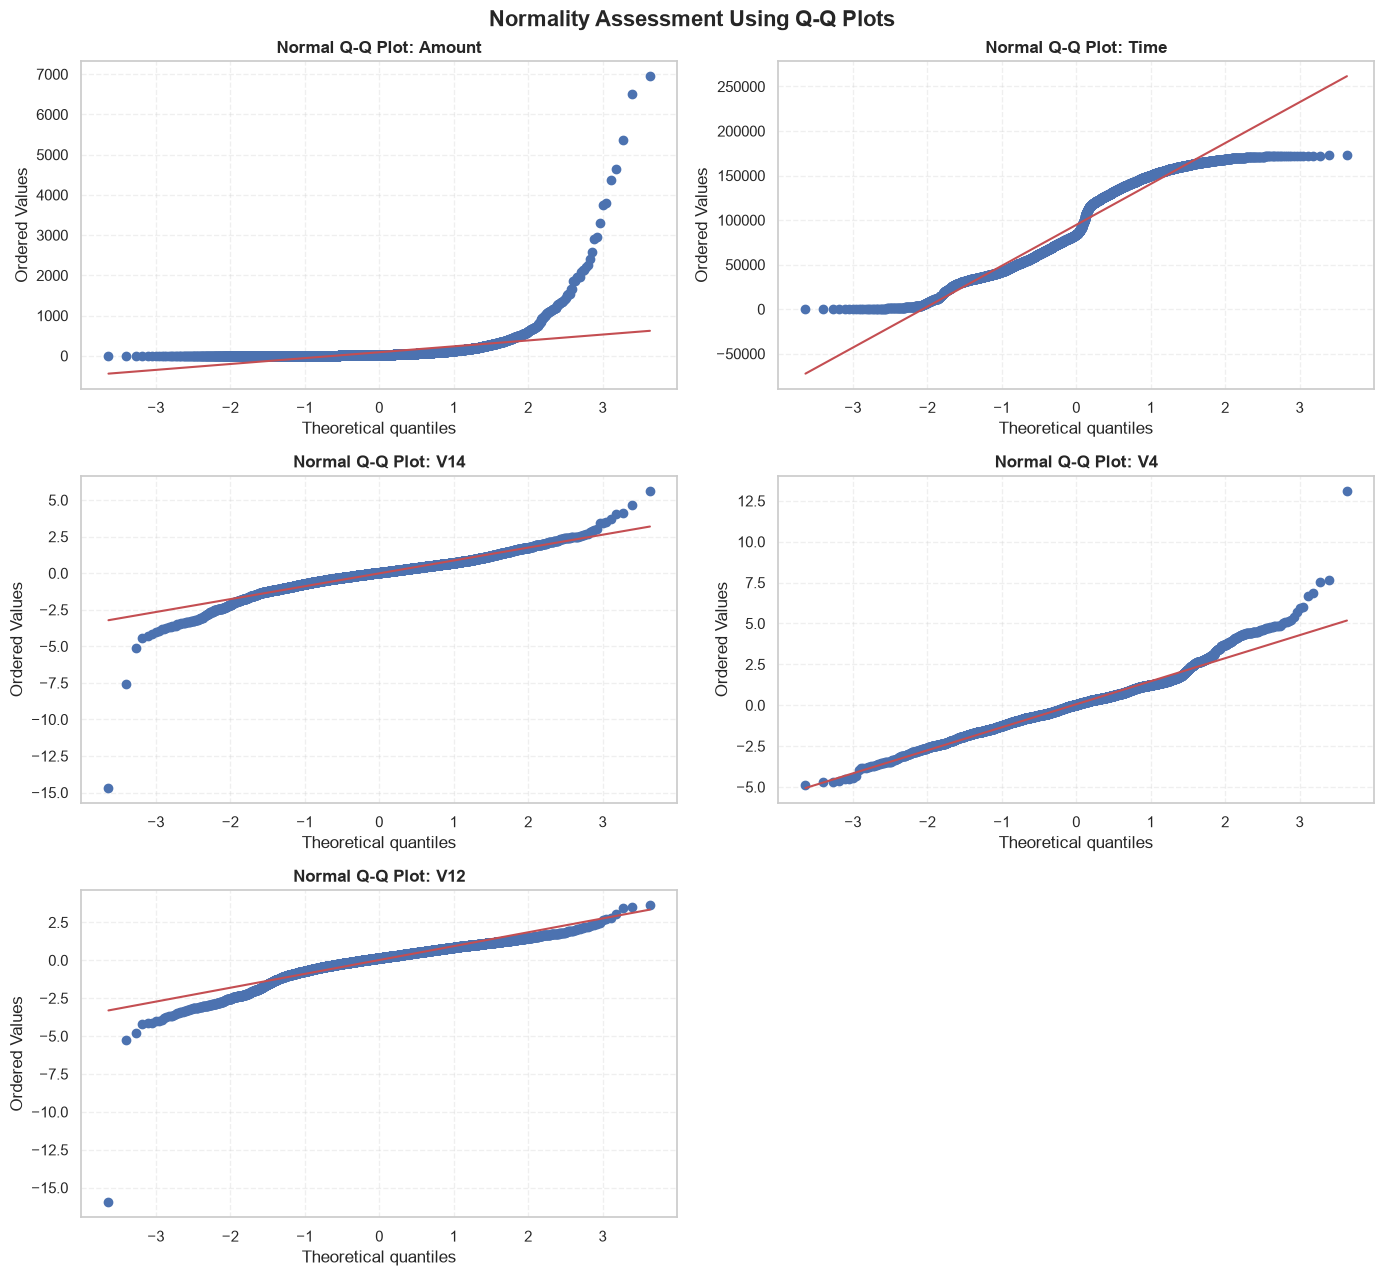

In [95]:
F_probplot()

In [96]:
from scipy.stats import normaltest

normality_results = []

for feature in normal_features:

    statistic, p_value = normaltest(normal_df[feature])

    normality_results.append({
        'Feature': feature,
        'K2 Statistic': statistic,
        'P Value': p_value,
        'Normality': (
            'Not Rejected'
            if p_value > 0.05
            else 'Rejected'
        )
    })

normality_results = pd.DataFrame(normality_results)

normality_results['Adjusted P Value'] = (multipletests(normality_results['P Value'],method='fdr_bh')[1])
normality_results['Adjusted Result'] = (normality_results['Adjusted P Value'].apply(lambda p: ('Not Rejected' if p > 0.05 else 'Rejected')))
normality_results.head()

,Feature,K2 Statistic,P Value,Normality,Adjusted P Value,Adjusted Result
0,Amount,41135.251666,0.0,Rejected,0.0,Rejected
1,Time,76632.665794,0.0,Rejected,0.0,Rejected
2,V14,12321.542292,0.0,Rejected,0.0,Rejected
3,V4,3501.647078,0.0,Rejected,0.0,Rejected
4,V12,13083.805670,0.0,Rejected,0.0,Rejected


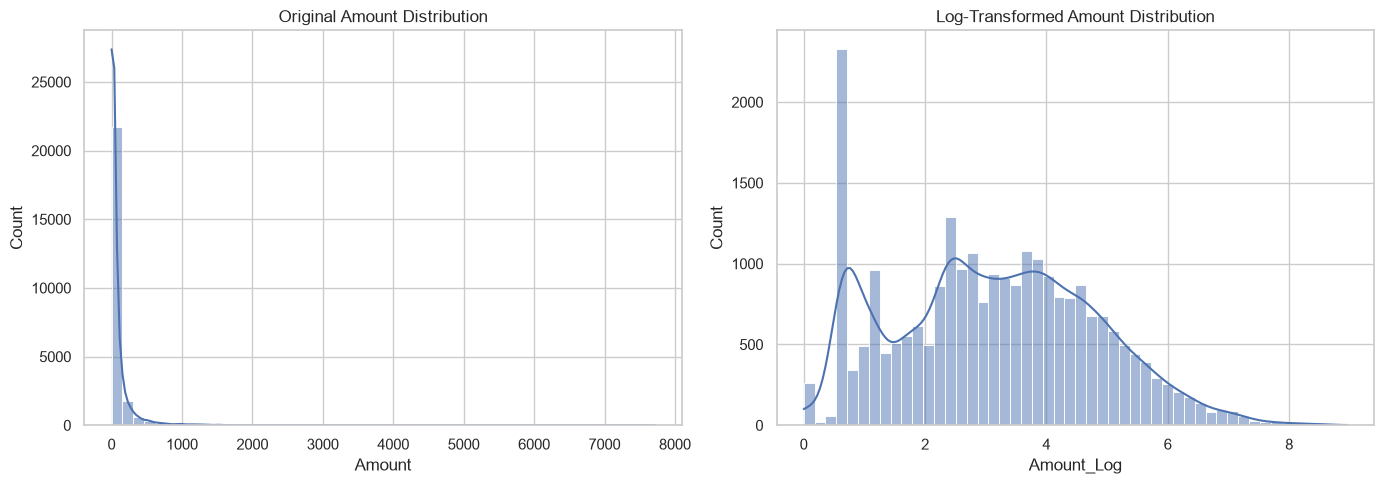

In [97]:
F_histplot_v4()

In [99]:
pd.DataFrame({
    'Original Amount': [
        normal_df['Amount'].skew(),
        normal_df['Amount'].kurt()
    ],
    'Log Amount': [
        normal_df['Amount_Log'].skew(),
        normal_df['Amount_Log'].kurt()
    ]
}, index=['Skewness', 'Kurtosis'])

,Original Amount,Log Amount
Skewness,10.978092,0.184291
Kurtosis,193.710175,-0.605828


##### 👨🏾‍🏫 Interpretation of Normal Distribution

The Normal Distribution analysis revealed that none of the five selected numerical features followed a statistically normal distribution.

The descriptive statistics highlighted substantial differences in their distributional characteristics. Transaction Amount presented a strong positive skewness (10.9781) and high kurtosis (193.7102), indicating a concentration of low-value transactions alongside a long right tail containing extreme values.

Time exhibited nearly zero skewness (-0.0360), suggesting an approximately symmetric distribution. However, its histogram revealed a multimodal pattern, indicating that symmetry alone is insufficient to establish normality.

The PCA components also showed deviations from a Normal Distribution. V14 and V12 presented negative skewness (-1.7422 and -2.0415, respectively) and high kurtosis (19.7545 and 16.1141). In contrast, V4 exhibited positive skewness (0.7271) and lower kurtosis (2.9132), although its distribution also showed deviations from the expected Normal shape.

These observations were supported by the D'Agostino-Pearson K² test, which rejected the null hypothesis of normality for all five features. The results remained significant after applying the Benjamini-Hochberg correction for multiple testing. The Q-Q plots further supported these findings, as the observations deviated from the theoretical reference lines, particularly in the distribution tails.

Finally, a logarithmic transformation was applied to the Amount feature. This reduced its skewness from 10.9781 to 0.1843 and its kurtosis from 193.7102 to -0.6058, demonstrating a substantial improvement in distribution symmetry and tail behaviour. Nevertheless, the transformed histogram still showed some irregularities, meaning that the transformation did not establish statistical normality.

Overall, the findings demonstrate that the selected numerical features exhibit different distributional characteristics and significant deviations from the Normal Distribution. This highlights the importance of evaluating distributional assumptions before applying statistical methods that rely on normality.

### ⚖ Statistical Comparison

In this final stage, we will bring together the results from the three distributions studied:

1. Binomial Distribution
2. Poisson Distribution
3. Normal Distribution


🎯  The objective is to compare their mathematical characteristics, assess their differences, and determine which distribution best represents the behavior of fraudulent transactions in the scenario under analysis.

An important methodological note: the Binomial and Poisson distributions were used to model the number of fraudulent instances within a scenario of 1,000 transactions, whereas the Normal distribution was examined to evaluate the behavior of the numerical variables in the dataset. Therefore, these should not be treated as three competing models applied to the exact same variable.

In [100]:
n_trials = 25_000
p = cleaned_df['Class'].mean()
lambda_poisson = n_trials * p

x = np.arange(0, 11)

binomial_prob = binom.pmf(x, n_trials, p)
poisson_prob = poisson.pmf(x, lambda_poisson)

distribution_comparison = pd.DataFrame({
    'Fraud Count': x,
    'Binomial Probability': binomial_prob,
    'Poisson Probability': poisson_prob
})

distribution_comparison['Absolute Difference'] = (
    distribution_comparison['Binomial Probability']
    - distribution_comparison['Poisson Probability']
).abs()

distribution_comparison['Difference (%)'] = (
    distribution_comparison['Absolute Difference'] * 100
)

distribution_comparison

,Fraud Count,Binomial Probability,Poisson Probability,Absolute Difference,Difference (%)
0,0,7.666068e-19,7.937377e-19,2.713087e-20,2.713087e-18
1,1,3.200363e-17,3.308103e-17,1.077395e-18,1.077395e-16
2,2,6.680032e-16,6.893678e-16,2.136462e-17,2.136462e-15
3,3,9.294995e-15,9.577050e-15,2.820550e-16,2.820550e-14
4,4,9.699821e-14,9.978696e-14,2.788755e-15,2.788755e-13
5,5,8.097498e-13,8.317749e-13,2.202511e-14,2.202511e-12
6,6,5.632995e-12,5.777721e-12,1.447262e-13,1.447262e-11
7,7,3.358642e-11,3.440017e-11,8.137477e-13,8.137477e-11
8,8,1.752180e-10,1.792143e-10,3.996261e-12,3.996261e-10
9,9,8.125009e-10,8.299121e-10,1.741116e-11,1.741116e-09


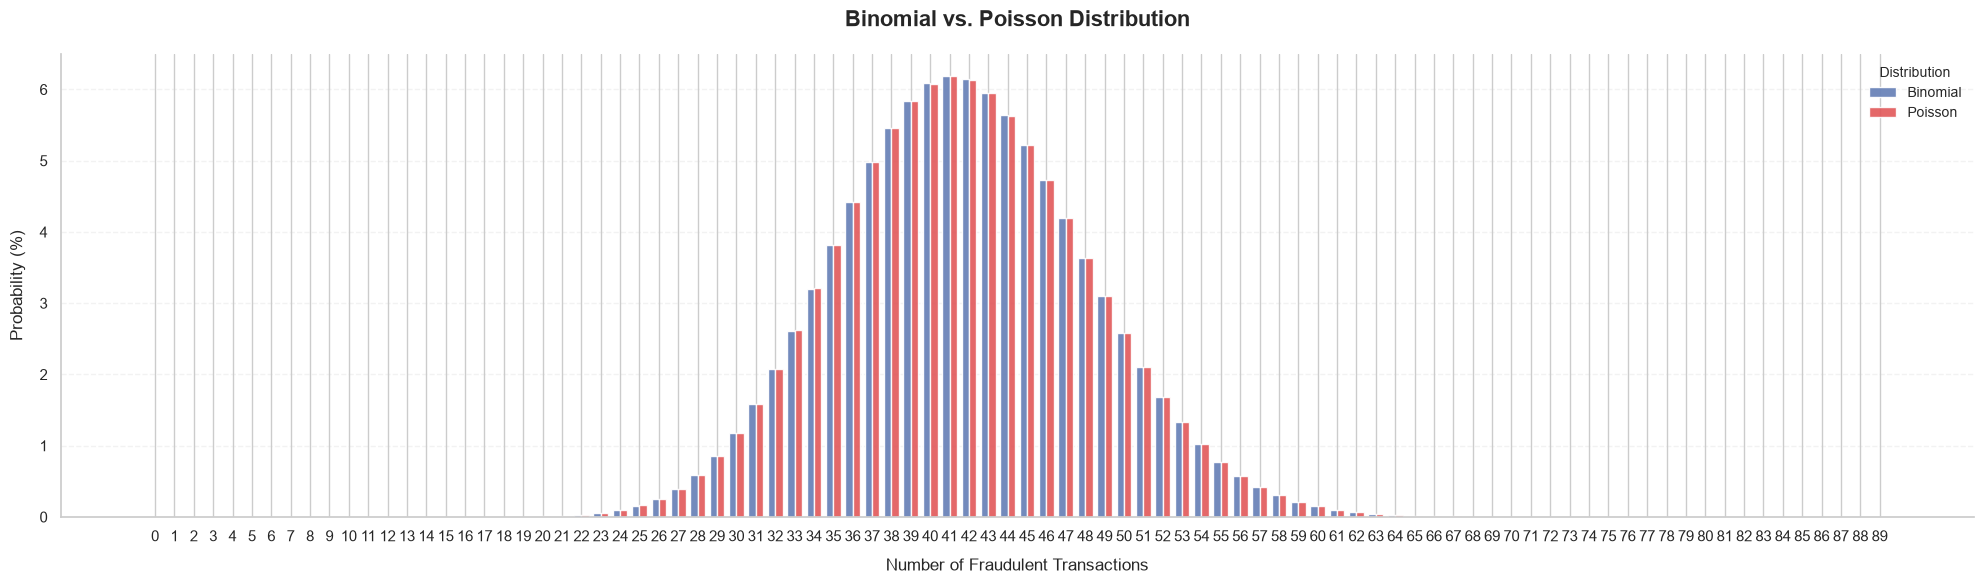

In [101]:
F_barplot_v8()

In [102]:
statistical_summary = pd.DataFrame(\
    {
        'Distribution': ['Binomial', 'Poisson', 'Normal'],
        'Expected Value': [n_trials * p, lambda_poisson, np.nan],
        'Variance': [n_trials * p * (1 - p), lambda_poisson, np.nan],
        'Standard Deviation': [np.sqrt(n_trials * p * (1 - p)), np.sqrt(lambda_poisson), np.nan],
        'Application': ['Fraud count in fixed trials', 'Approximation of fraud counts', 'Numerical feature analysis'],
        'Findings': ['Reference distribution', 'Very close approximation', 'Selected features rejected normality']
    })

statistical_summary

,Distribution,Expected Value,Variance,Standard Deviation,Application,Findings
0,Binomial,41.677534,41.608053,6.450430,Fraud count in fixed trials,Reference distribution
1,Poisson,41.677534,41.677534,6.455814,Approximation of fraud counts,Very close approximation
2,Normal,NaN,NaN,NaN,Numerical feature analysis,Selected features rejected normality


##### 👨🏾‍🏫 Statistical Comparison — Conclusion

The statistical comparison brought together the findings from the Binomial, Poisson, and Normal distribution analyses to evaluate their suitability for understanding fraudulent transactions.

The Binomial Distribution was established as the reference model for estimating fraudulent transactions within a fixed sample of `25,000` operations. Using an estimated fraud probability of approximately `0.0016671`, the expected number of fraudulent transactions was `41.6775`, with a variance of `41.6081` and a standard deviation of `6.4504`.

The Poisson Distribution produced an expected value and variance of approximately `41.6775`, with a standard deviation of `6.4558`. Its probability estimates were remarkably close to those obtained from the Binomial model. Across the evaluated fraud counts from `0` to `89`, the maximum absolute probability difference was approximately `0.00005148`, while the mean absolute difference was approximately `0.00000899`. These results demonstrate that the Poisson Distribution provides a close approximation under the selected parameters.

In contrast, the Normal Distribution analysis revealed significant deviations from normality across all five selected numerical features. These findings were supported by descriptive statistics, histograms, Q-Q plots, and the D'Agostino-Pearson normality test, including the Benjamini-Hochberg correction.

Although the selected numerical features did not follow a Normal Distribution, a Normal approximation to the Binomial model may be considered because both `np` and `n(1-p)` exceed five. However, this approximation was not explicitly evaluated in the current analysis.

Overall, the comparison demonstrates that the Binomial Distribution provides an appropriate framework for modeling fraud counts under the specified assumptions, while the Poisson Distribution offers a close approximation. The Normal Distribution analysis, meanwhile, highlights the non-normal characteristics of the selected numerical features.

These findings provide a statistical foundation for understanding the dataset and support the subsequent development of machine learning models for credit card fraud detection.

⚠⚠⚠ Warning ⚠⚠⚠

- Independence assumption: transactions were treated as independent trials with a constant probability of fraud. This is a modeling assumption, not something proven by the EDA (Exploratory Data Analysis).

- Selected sample size: the scenario involving `25,000` transactions is a statistical simulation based on the observed fraud rate; it does not imply that the transactions were grouped into actual blocks of `25,000`.

### 🔗 Refence...

- D’Agostino, R. and Pearson, E.S. (1973) ‘Tests for departure from normality. Empirical results for the distributions of b² and √b¹’, *Biometrika*, 60(3), pp. 613–622. doi: 10.1093/biomet/60.3.613.

- Harris, C.R., Millman, K.J., van der Walt, S.J. et al. (2020) ‘Array programming with NumPy’, Nature, 585, pp. 357–362. Available at: https://doi.org/10.1038/s41586-020-2649-2 (Accessed: 1 November 2026). 

- Hunter, J.D. (2007) ‘Matplotlib: A 2D graphics environment’, Computing in Science & Engineering, 9(3), pp. 90–95. Available at: https://doi.org/10.1109/MCSE.2007.55 (Accessed: 1 November 2026).

- Machine Learning Group - ULB (n.d.) Credit Card Fraud Detection. Kaggle. Available at: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud (Accessed: 1 November 2026).

- OpenAI (2026) *ChatGPT: Assistance with Python, Matplotlib data visualisation and statistical analysis*. Conversation with ChatGPT, 1 November 2026. Available at: https://chatgpt.com/share/6ae7a1b1-47e0-83ed-ab71-e8d4866fe56b (Accessed: 1 November 2026).

- OpenAI (2026) ChatGPT: Assistance with statistical data analysis, descriptive statistics and probability distributions using Python. Conversation with ChatGPT, 1 November 2026. Available at: https://chatgpt.com/share/6ae7a224-bad0-83ed-9a70-b406b4fcf6af (Accessed: 1 November 2026).

- Pandas (n.d.) pandas.DataFrame.kurt — Return unbiased kurtosis over requested axis. pandas Documentation. Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.kurt.html (Accessed: 1 November 2026).

- Pennsylvania State University (n.d.) The Binomial Distribution. STAT 414: Introduction to Probability Theory. Available at: https://online.stat.psu.edu/stat414/Lesson10 (Accessed: 1 November 2026).

- Pennsylvania State University (n.d.) *Approximations for Discrete Distributions*. STAT 414: Introduction to Probability Theory. Available at: https://online.stat.psu.edu/stat414/Lesson28 (Accessed: 1 November 2026).

- RMIT University (n.d.) *Poisson Distribution*. Learning Lab. Available at: https://learninglab.rmit.edu.au/maths-statistics/statistics/s19-poisson-distribution/ (Accessed: 1 November 2026).

- SciPy (n.d.) *scipy.stats.binom — Binomial Distribution*. Available at: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binom.html (Accessed: 1 November 2026).

- SciPy (n.d.) *scipy.stats.norm — Normal Distribution*. Available at: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html (Accessed: 1 November 2026).

- SciPy (n.d.) *scipy.stats.normaltest — Normality Test*. Available at: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.normaltest.html (Accessed: 1 November 2026).

- SciPy (n.d.) *scipy.stats.poisson — Poisson Distribution*. Available at: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html (Accessed: 1 November 2026).

- Waskom, M.L. (2021) ‘seaborn: Statistical data visualization’, Journal of Open Source Software, 6(60), article 3021. Available at: https://doi.org/10.21105/joss.03021 (Accessed: 1 November 2026).